# Debugging the electrode conductivity: why do conducting electrodes barely change the assignment?

On 2026-11-10 the 2- and 3-fish silent controls were run with my numerical model (shape only) at N = 200 in the measured tank
(`eod_assignment_control_groups.py --geometry tank`: non-conductive walls along the fitted outline with the 2 cm cut-out at the top
left, electrodes moved just inside the walls / into the corners, 14.2 px/cm), with and without the recording electrodes as
conducting discs (graphite, 1e7 x water). Accuracy barely moved (clean good frames: 2-fish 98.96 → 98.88 %, 3-fish 98.33 → 98.27 %
with discs of 0.5 cm).

Here: for each video, 20 clean-good EODs whose true emitter lies **next to a wall or in a corner** (the cut-out top-left corner
included): 10 that the model with electrodes (r 0.5 cm) assigns correctly and 10 it gets wrong. For each EOD:

- **A** the video frame with the tank outline, every fish's mask and the electrodes (discs of 0.5 cm);
- **B** a zoom on the emitter in the model's grid (N = 200, cell 0.32 cm): nodes outside the walls (dark), electrode-disc nodes
  (blue), the masks and the emitter's midline (current poles, sink at the tail tip);
- **C** how much the electrodes change the emitter's potential: φ(discs) − φ(no discs), relative to the largest |φ| in the zoom;
- **D** the 10 pair voltages at the recorded peak: recorded (black) and each fish's model (colour per fish; solid = with
  electrodes, dashed = without), each scaled to max |v| = 1, model × −1 (`MODEL_SIGN`);
- **middle row** each fish's mask zoomed in on the grid: the mask (filled), the body the model uses (outline of the occupancy
  > 0.5 on the grid nodes), the fish's midline, walls and electrode discs;
- **E, F** the recorded EOD (black) on the two pairs with the largest recorded peak, and each fish's predicted EOD there (solid =
  with electrodes, dashed = without). The model is resistive, so it predicts one number per pair; its trace is that number times
  the recording's common EOD waveform (rank-1 waveform of the 10 pairs, 1 at the peak sample), with the model's pattern scaled
  so its largest pair equals the recording's largest |peak| (the scaling of panel D, in recorded units).

Only clean-good EODs (clean good frames: mask QC + every fish's length ≥ 0.8 × its median).

The last section measures the electrode effect on every clean-good EOD against the emitter's distance to the nearest electrode.

Selection: emitter midline (saved per video in `mask_midlines_by_frame_newest.npz`) within 5 cm of the cut-out's inner corner →
*top left*; within 5 cm of another tank corner → *corner*; else within 1.5 cm of a wall → *wall*. Per outcome 4 top left,
3 corner, 3 wall (filled from the other regions when one has too few), random with seed 0, clean good frames only
(mask QC + length ≥ 0.8 × median, no SLEAP rule). Correct / wrong refers to the run with electrodes (r 0.5 cm).

In [1]:
import os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Circle, Rectangle
import eod_examples as ex
import eod_assignment_control_groups as g
from compute_electric_field import (occupancy_field, build_A_shell, solve_potential, build_multipole_b, multipole_sources,
                                    confine_sources, unflatten_to_grid, electrode_occupancy, electrode_points, PX_PER_CM)
from eod_assign import pair_voltages, MODEL_SIGN, recorded_pair_traces, peak_pattern, rank1_pattern, eod_sample_count
%matplotlib inline

N, P, FPS, FS_EOD = 200, 912, 50, 50000.0              # video fps, electrode sampling rate (Hz)
H = 1 / (N - 1)
REC = {'2-fish': dict(res='results/eod_ground_truth', video='data/2_fish_silent/video2024-02-13T14_33_21.avi', emitter=1),
       '3-fish': dict(res='results/eod_ground_truth_3fish', video='data/3_fish_silent/video2024-10-15T14_12_25.avi', emitter=0)}
VER = {'no discs': 'N200_tank_none', 'discs r 0.5 cm': 'N200_tank_r0.5_s1e7'}
FISH_COL = ['#2a78d6', '#eb6834', '#1baf7a']          # fish 0, 1, 2 (fixed per fish)
WALL_CM, CORNER_CM, N_PER, SEED = 1.5, 5.0, dict(top_left=4, corner=3, wall=3), 0
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d03b2b'])
OUT = {rec: f"{g.REC[rec]['out']}/debug_electrodes" for rec in REC}
for d in OUT.values(): os.makedirs(d, exist_ok=True)

## 1. Data: results of both runs, clean-good flags, midlines, tank outline

In [2]:
DATA = {}
for rec, r in REC.items():
    c = g.REC[rec]
    res = {v: pd.read_csv(f"{c['out']}/{tag}/eod_assignment_shape.csv") for v, tag in VER.items()}
    q = pd.read_csv(f"{r['res']}/eod_clean_good_synch_fix_newest.csv")
    assert all((x.Frame.to_numpy() == q.Frame.to_numpy()).all() for x in res.values())
    z = np.load(c['midlines'])
    DATA[rec] = dict(res=res, clean=q.clean_good.to_numpy(bool), outline=pd.read_csv(c['outline'])[['x', 'y']].to_numpy(),
                     mid_px=dict(zip(z['frames'].tolist(), z['midlines_px'])), mid_tank=dict(zip(z['frames'].tolist(), z['midlines_tank'])),
                     el=pd.read_csv(c['electrodes_updated']),
                     traces=pd.read_csv(c['newest'], usecols=lambda col: col.startswith('electrode_')))
    DATA[rec]['n_samp'] = eod_sample_count(DATA[rec]['traces'])
    print(rec, {v: len(x) for v, x in res.items()}, 'EODs;', DATA[rec]['clean'].sum(), 'clean good')

2-fish {'no discs': 18801, 'discs r 0.5 cm': 18801} EODs; 11803 clean good


3-fish {'no discs': 19796, 'discs r 0.5 cm': 19796} EODs; 8972 clean good


## 2. Selection: emitter next to a wall or in a corner

In [3]:
def wall_and_corner_distances(Pts, V):
    '''Pts (n, 2) px -> (distance to the nearest wall, to the cut-out inner corner V[5], to the nearest other corner), cm.'''
    E = np.roll(V, -1, 0) - V
    t = np.clip(((Pts[:, None] - V[None]) * E[None]).sum(-1) / (E ** 2).sum(-1), 0, 1)
    dw = np.linalg.norm(Pts[:, None] - (V[None] + t[..., None] * E[None]), axis=-1).min()
    dtl = np.linalg.norm(Pts - V[5], axis=1).min()
    dc = min(np.linalg.norm(Pts - V[j], axis=1).min() for j in (1, 2, 3))      # tr, br, bl
    return dw / PX_PER_CM, dtl / PX_PER_CM, dc / PX_PER_CM

SEL = {}
for rec, r in REC.items():
    D, em = DATA[rec], r['emitter']; d = D['res']['discs r 0.5 cm']
    rows = []
    for i in np.flatnonzero(D['clean']):
        Pts = D['mid_px'][int(d.Frame[i])][em]
        if not np.isfinite(Pts).all(): continue
        rows.append((i, *wall_and_corner_distances(Pts, D['outline'])))
    t = pd.DataFrame(rows, columns=['eod_row', 'wall_cm', 'top_left_cm', 'corner_cm']).set_index('eod_row')
    t['region'] = np.where(t.top_left_cm <= CORNER_CM, 'top_left', np.where(t.corner_cm <= CORNER_CM, 'corner',
                           np.where(t.wall_cm <= WALL_CM, 'wall', '')))
    t['correct'] = (d.pick.to_numpy() == em)[t.index]
    t = t[t.region != '']
    rng = np.random.default_rng(SEED); pick = []
    for ok in (True, False):
        pool = t[t.correct == ok]; chosen = []
        for reg, n in N_PER.items():
            cand = pool.index[pool.region == reg].to_numpy()
            chosen += list(rng.choice(cand, min(n, len(cand)), replace=False))
        rest = np.setdiff1d(pool.index, chosen)                              # fill up to 10 from the other regions
        chosen += list(rng.choice(rest, 10 - len(chosen), replace=False))
        pick.append(t.loc[chosen].assign(outcome='correct' if ok else 'wrong'))
    SEL[rec] = pd.concat(pick).assign(Frame=lambda x: d.Frame.to_numpy()[x.index])
    print(f"{rec}: clean-good EODs with the emitter by a wall / in a corner:")
    display(t.groupby(['correct', 'region']).size().unstack(fill_value=0))
    display(SEL[rec].round(2))
    SEL[rec].to_csv(f"{OUT[rec]}/selected_eods.csv")

2-fish: clean-good EODs with the emitter by a wall / in a corner:


region,corner,top_left,wall
correct,,,
False,12,20,48
True,1508,1382,5496


,wall_cm,top_left_cm,corner_cm,region,correct,outcome,Frame
eod_row,,,,,,,
3071,2.11,4.63,36.76,top_left,True,correct,6141
8012,0.68,2.00,44.78,top_left,True,correct,17592
13901,0.99,1.31,46.29,top_left,True,correct,32836
9170,0.01,2.06,44.64,top_left,True,correct,20339
1068,1.60,39.69,3.49,corner,True,correct,1802
16788,0.90,39.34,2.82,corner,True,correct,41702
7206,0.54,39.19,4.35,corner,True,correct,15601
12631,0.01,49.76,5.74,wall,True,correct,29479
14997,1.20,16.79,24.89,wall,True,correct,35261


3-fish: clean-good EODs with the emitter by a wall / in a corner:


region,corner,top_left,wall
correct,,,
False,5,13,5
True,96,747,73


,wall_cm,top_left_cm,corner_cm,region,correct,outcome,Frame
eod_row,,,,,,,
2054,0.01,2.41,49.53,top_left,True,correct,3062
2884,0.01,0.26,49.97,top_left,True,correct,4383
3573,0.02,1.90,48.72,top_left,True,correct,5544
3187,0.01,0.16,48.66,top_left,True,correct,4970
10188,1.55,52.76,4.04,corner,True,correct,15040
18907,0.02,46.36,4.39,corner,True,correct,32628
10973,1.47,54.15,3.06,corner,True,correct,16088
10192,0.94,51.00,5.26,wall,True,correct,15045
14670,0.62,10.17,38.08,wall,True,correct,21242


## 3. Plots

Panel B shows the grid as the model sees it: each square is one node's cell (0.32 cm); dark = outside the walls (no current),
light = water, blue = electrode disc (conductivity 1e7 x water); masks of the other fish (bodies) filled, the emitter's mask
outlined (its body is transparent in the model) and its midline with the current poles (sink = black dot at the tail tip).
Panel C: the change in the emitter's potential caused by the discs, in % of the largest |φ| in the zoom without discs. Panel D:
legend gives each fish's L2 distance to the recording with / without discs; the pick is the smallest L2.

In [4]:
CTX = {rec: {v: g.context(rec, N, [None if v == 'no discs' else (0.5, 1e7)], 'tank') for v in VER} for rec in REC}

def video_frame(path, k):
    raw = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / FPS:.4f}', '-i', path, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(raw, np.uint8).reshape(P, P)

def emitter_fields(rec, k, em):
    '''Emitter's potential (N, N) without and with discs, and the solved pair voltages (to check against the run).'''
    out = {}
    for v, ctx in CTX[rec].items():
        fm = ex.frame_masks(ctx, k); mid = DATA[rec]['mid_tank'][k][em]
        b = confine_sources(build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=g.SINK), H, N), ctx['inside'])
        phi = unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fm, N, skip=em), N, **ctx['mat'],
                                                              electrodes=ctx['elec'][0], inside=ctx['inside']), b), N).real
        out[v] = (phi, pair_voltages(phi, ctx['pairs'], N))
    return out, fm

def norm(v): return v / np.nanmax(np.abs(v))

def plot_example(rec, i, info, n_in_set):
    r, D = REC[rec], DATA[rec]; em = r['emitter']; k = int(info.Frame)
    res = D['res']; ctx = CTX[rec]['discs r 0.5 cm']; pair_ids = [p for p, _, _ in ctx['pairs']]; nf = len(ctx['fish'])
    fields, fm = emitter_fields(rec, k, em)
    U = {v: np.stack([[x.loc[i, f'u{f}_raw_p{q}'] for q in pair_ids] for f in range(nf)]) for v, x in res.items()}
    for v in VER: assert np.allclose(fields[v][1], U[v][em], rtol=1e-8, atol=1e-12 * np.abs(U[v][em]).max())
    R = res['discs r 0.5 cm'].loc[i, [f'r_raw_p{q}' for q in pair_ids]].to_numpy(float)
    L2 = {v: [x.loc[i, f'd{f}'] for f in range(nf)] for v, x in res.items()}
    picks = {v: int(x.pick[i]) for v, x in res.items()}
    V, el = D['outline'], D['el']; pts = electrode_points(ctx['pairs'])[:, ::-1] * (P - 1)          # (x, y) px
    labels = [f"{p}{s}" for _, row in el.iterrows() for p, s in ((row.pair, row.pol1), (row.pair, row.pol2))]
    mid = D['mid_px'][k][em]; cx, cy = np.nanmean(mid, axis=0); half = 9 * PX_PER_CM
    x0, x1 = max(cx - half, 0), min(cx + half, P - 1); y0, y1 = max(cy - half, 0), min(cy + half, P - 1)
    gpx = np.arange(N) / (N - 1) * (P - 1); cell = gpx[1] - gpx[0]
    ext = (gpx[0] - cell / 2, gpx[-1] + cell / 2, gpx[-1] + cell / 2, gpx[0] - cell / 2)

    fig = plt.figure(figsize=(25, 17.5)); gs = fig.add_gridspec(3, 12, height_ratios=[1, 0.95, 0.62])
    ax = [fig.add_subplot(gs[0, 0:3]), fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:9]), fig.add_subplot(gs[0, 9:12])]
    w = 12 // nf; axf = [fig.add_subplot(gs[1, j * w:(j + 1) * w]) for j in range(nf)]
    axe = [fig.add_subplot(gs[2, 0:6]), fig.add_subplot(gs[2, 6:12])]
    # A: video, outline, masks, electrodes
    img = video_frame(r['video'], k); lo, hi = np.percentile(img, [1, 99.5])
    ax[0].imshow(img, cmap='gray', vmin=lo, vmax=hi)
    ax[0].plot(*np.vstack([V, V[:1]]).T, '-', color='#eda100', lw=1.2)
    for f in range(nf):
        if fm[f].any(): ax[0].contour(fm[f], [0.5], colors=FISH_COL[f], linewidths=1.6)
    for (x, y), lab in zip(pts, labels):
        ax[0].add_patch(Circle((x, y), 0.5 * PX_PER_CM, fc='#d03b2b', ec='none'))
        ax[0].text(x + (8 if x < 456 else -8), y + (16 if y < 456 else -8), lab, color='#d03b2b', fontsize=7,
                   ha='left' if x < 456 else 'right')
    ax[0].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='w', lw=1, ls='--'))
    ax[0].set_title(f'A  video frame {k}: masks (fish colour), electrodes (red)', fontsize=10)
    # B: grid view
    lab = ctx['inside'].astype(int); lab[ctx['elec'][0][0] > 0.5] = 2
    ax[1].imshow(lab, cmap=ListedColormap(['#3a3a38', '#f7f7f5', '#86b6ef']), vmin=-0.5, vmax=2.5, extent=ext, interpolation='nearest')
    for xg in np.arange(N + 1) * cell - cell / 2:
        ax[1].axvline(xg, color='0.82', lw=0.4); ax[1].axhline(xg, color='0.82', lw=0.4)
    for f in range(nf):
        if not fm[f].any(): continue
        if f == em: ax[1].contour(fm[f], [0.5], colors=FISH_COL[f], linewidths=1.8)
        else: ax[1].imshow(np.ma.masked_where(~fm[f], np.ones_like(fm[f], float)), cmap=ListedColormap([FISH_COL[f]]), alpha=0.45)
    ax[1].plot(mid[:, 0], mid[:, 1], '.-', color=FISH_COL[em], ms=2.5, lw=0.8)
    ax[1].plot(*mid[int(round(g.SINK * (len(mid) - 1)))], 'o', color='k', ms=5)
    for (x, y), lb in zip(pts, labels):
        ax[1].add_patch(Circle((x, y), 0.5 * PX_PER_CM, fill=False, ec='#2a78d6', lw=1.2))
        if x0 <= x <= x1 and y0 <= y <= y1: ax[1].text(x + 9, y - 6, lb, color='#184f95', fontsize=8, fontweight='bold')
    ax[1].plot(*np.vstack([V, V[:1]]).T, '-', color='#eda100', lw=1.2)
    ax[1].set_title(f'B  model grid N {N}: walls (dark), discs (blue), emitter midline', fontsize=10)
    # C: change of the emitter's potential by the discs
    p0, p1 = fields['no discs'][0], fields['discs r 0.5 cm'][0]
    win = np.ix_((gpx >= y0) & (gpx <= y1), (gpx >= x0) & (gpx <= x1))
    dphi = (p1 - p0) / np.nanmax(np.abs(p0[win])) * 100; lim = max(np.nanmax(np.abs(dphi[win])), 1e-3)
    im = ax[2].imshow(dphi, cmap=DIV, vmin=-lim, vmax=lim, extent=ext, interpolation='nearest')
    for f in range(nf):
        if fm[f].any(): ax[2].contour(fm[f], [0.5], colors=FISH_COL[f], linewidths=1.2)
    for x, y in pts: ax[2].add_patch(Circle((x, y), 0.5 * PX_PER_CM, fill=False, ec='k', lw=1))
    ax[2].plot(*np.vstack([V, V[:1]]).T, '-', color='#eda100', lw=1.2)
    fig.colorbar(im, ax=ax[2], shrink=0.75, label='Δφ, % of max |φ| in the zoom')
    ax[2].set_title("C  emitter's φ(discs) − φ(no discs)", fontsize=10)
    for a in ax[:3]:
        a.set_xlabel('x (px, video column)'); a.set_ylabel('y (px, video row, down)')
    ax[0].set_xlim(0, P - 1); ax[0].set_ylim(P - 1, 0)
    for a in ax[1:3]: a.set_xlim(x0, x1); a.set_ylim(y1, y0)
    # D: recorded vs predicted pair voltages
    xq = np.arange(len(pair_ids)); a = ax[3]
    a.plot(xq, norm(R), 'o-', color='k', lw=2.2, ms=7, label='recorded', zorder=5)
    for f in range(nf):
        for v, ls, mk in (('discs r 0.5 cm', '-', 's'), ('no discs', '--', None)):
            u = U[v][f]
            if not np.isfinite(u).all(): continue
            a.plot(xq, norm(MODEL_SIGN * u), ls, color=FISH_COL[f], lw=1.8 if ls == '-' else 1.4, marker=mk, ms=5,
                   label=f"fish {f}{' (true)' if f == em else ''}, {v}: L2 {L2[v][f]:.3f}")
    a.axhline(0, color='0.6', lw=0.8); a.set_xticks(xq, pair_ids); a.set_xlabel('electrode pair')
    a.set_ylabel('voltage / max |v|'); a.legend(fontsize=7.5, frameon=False, loc='best')
    for s in ('top', 'right'): a.spines[s].set_visible(False)
    a.set_title(f"D  pick with discs: fish {picks['discs r 0.5 cm']}, without: fish {picks['no discs']} (true: fish {em})", fontsize=10)
    # bottom row: each fish's mask zoomed in on the grid
    for f, af in enumerate(axf):
        af.imshow(lab, cmap=ListedColormap(['#3a3a38', '#f7f7f5', '#86b6ef']), vmin=-0.5, vmax=2.5, extent=ext, interpolation='nearest')
        if not fm[f].any():
            af.set_title(f'fish {f}: no mask', fontsize=10); af.axis('off'); continue
        yy, xx = np.nonzero(fm[f]); pad = 1.5 * PX_PER_CM
        bx0, bx1, by0, by1 = xx.min() - pad, xx.max() + pad, yy.min() - pad, yy.max() + pad
        side = max(bx1 - bx0, by1 - by0); mx, my = (bx0 + bx1) / 2, (by0 + by1) / 2
        for xg in np.arange(N + 1) * cell - cell / 2:
            af.axvline(xg, color='0.82', lw=0.4); af.axhline(xg, color='0.82', lw=0.4)
        af.imshow(np.ma.masked_where(~fm[f], np.ones_like(fm[f], float)), cmap=ListedColormap([FISH_COL[f]]), alpha=0.5)
        af.contour(gpx, gpx, occupancy_field(fm[[f]], N), [0.5], colors='k', linewidths=1.2)
        mf = D['mid_px'][k][f]
        if np.isfinite(mf).all():
            af.plot(mf[:, 0], mf[:, 1], '.-', color='k', ms=2, lw=0.7); af.plot(*mf[0], 'o', color='k', ms=4)
        for (x, y), lb in zip(pts, labels):
            af.add_patch(Circle((x, y), 0.5 * PX_PER_CM, fill=False, ec='#2a78d6', lw=1.2))
            if abs(x - mx) < side / 2 and abs(y - my) < side / 2: af.text(x + 9, y - 6, lb, color='#184f95', fontsize=8, fontweight='bold')
        af.plot(*np.vstack([V, V[:1]]).T, '-', color='#eda100', lw=1.2)
        af.set_xlim(mx - side / 2, mx + side / 2); af.set_ylim(my + side / 2, my - side / 2)
        af.set_title(f"fish {f}{' (true emitter)' if f == em else ''}: mask (filled), model body on the grid (black outline), "
                     f"midline (tail = dot)", fontsize=9)
        af.set_xlabel('x (px)'); af.set_ylabel('y (px)')
    # E, F: recorded vs predicted EOD on the two pairs with the largest recorded peak
    Vt = recorded_pair_traces(D['traces'].iloc[i], pair_ids, D['n_samp'])
    rpk, ts = peak_pattern(Vt); assert np.allclose(rpk, R)
    _, wv, frac = rank1_pattern(Vt); wv = wv / wv[ts]
    tms = (np.arange(Vt.shape[1]) - ts) / FS_EOD * 1e3; rmax = np.abs(rpk).max()
    for n_top, (a, j) in enumerate(zip(axe, np.argsort(-np.abs(rpk))[:2]), 1):
        a.plot(tms, Vt[j], 'o-', color='k', lw=2.2, ms=4, label='recorded', zorder=5)
        for f in range(nf):
            for v, ls in (('discs r 0.5 cm', '-'), ('no discs', '--')):
                u = U[v][f]
                if not np.isfinite(u).all(): continue
                a.plot(tms, norm(MODEL_SIGN * u)[j] * rmax * wv, ls, color=FISH_COL[f], lw=1.8 if ls == '-' else 1.3,
                       label=f"fish {f}{' (true)' if f == em else ''}, {v}")
        a.axhline(0, color='0.6', lw=0.8); a.axvline(0, color='0.75', lw=0.8, ls=':')
        a.set_xlabel('time from the recorded peak sample (ms)'); a.set_ylabel('voltage (recorded units)')
        a.set_title(f"{'EF'[n_top - 1]}  pair {pair_ids[j]}: largest recorded peak no. {n_top} ({rpk[j]:+.3g}); model = its pattern "
                    f"x the recorded EOD waveform (rank 1: {frac:.0%} of the variance)", fontsize=10)
        for s_ in ('top', 'right'): a.spines[s_].set_visible(False)
    axe[0].legend(fontsize=8, frameon=False, ncol=2)
    d_el = np.linalg.norm(mid[:, None] - pts[None], axis=-1).min() / PX_PER_CM
    change = np.abs(norm(MODEL_SIGN * U['discs r 0.5 cm'][em]) - norm(MODEL_SIGN * U['no discs'][em])).max()
    fig.suptitle(f"{rec}, {info.outcome} {n_in_set}/10 — EOD row {i}, frame {k}, {info.region.replace('_', ' ')}: emitter "
                 f"{info.wall_cm:.1f} cm from a wall, {d_el:.1f} cm from the nearest electrode centre; max change of the emitter's "
                 f"normalised pattern by the discs {change:.3f}", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    fig.savefig(f"{OUT[rec]}/{rec}_{info.outcome}_{n_in_set:02d}_frame{k}.png", dpi=110); plt.show(); plt.close(fig)
    return dict(rec=rec, outcome=info.outcome, eod_row=i, Frame=k, region=info.region, wall_cm=info.wall_cm, electrode_cm=d_el,
                pattern_change=change, pick_discs=picks['discs r 0.5 cm'], pick_none=picks['no discs'],
                **{f'L2 fish {f} | {v}': L2[v][f] for v in VER for f in range(nf)})

### 2-fish: correct assignments (emitter by a wall / in a corner)

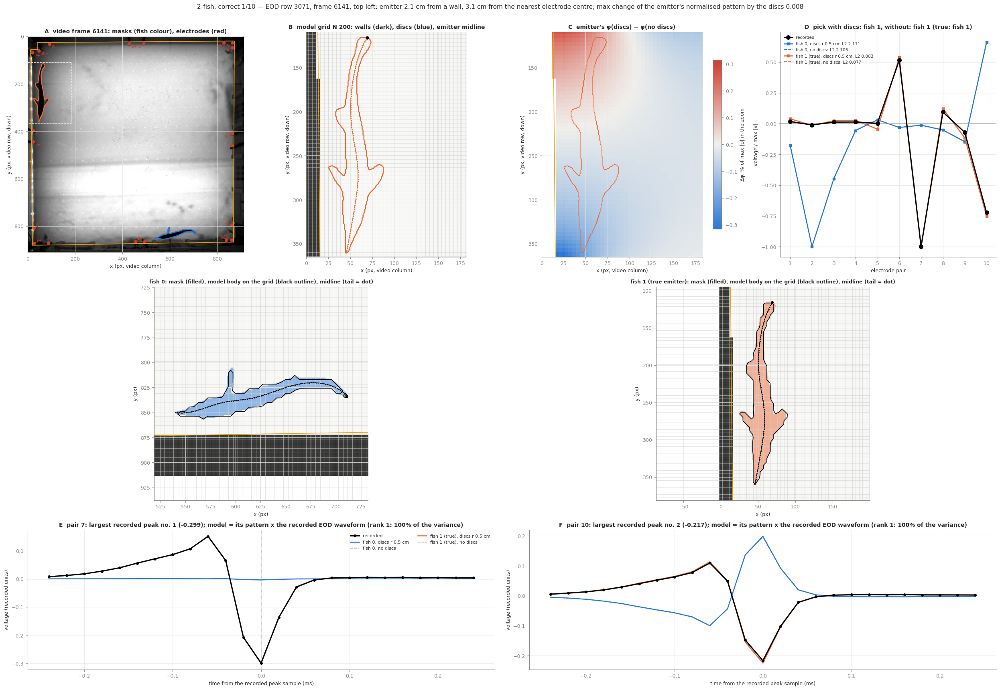

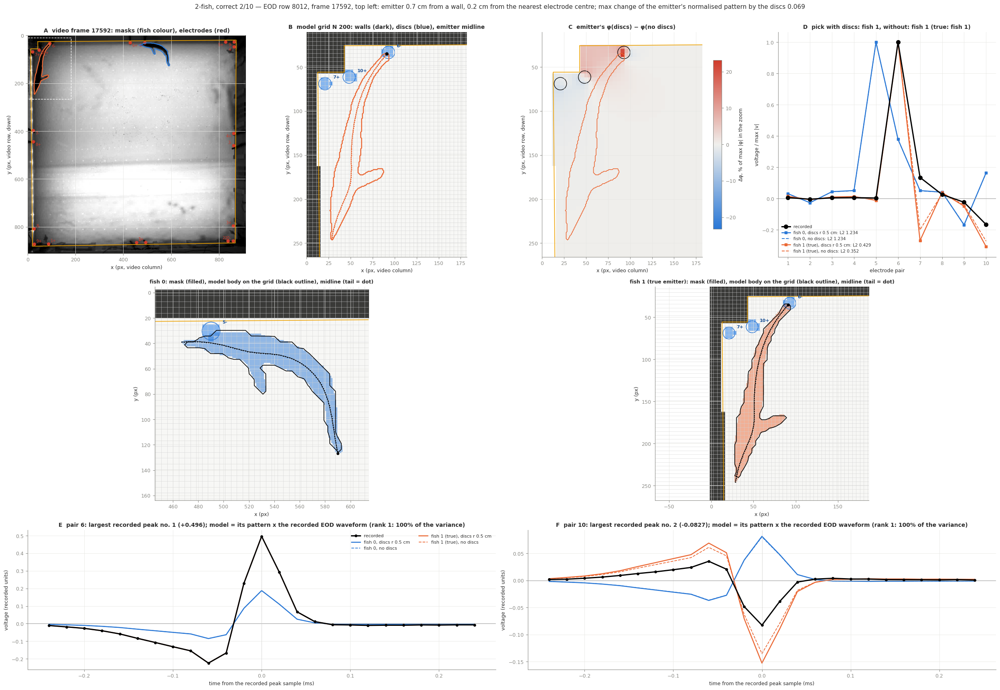

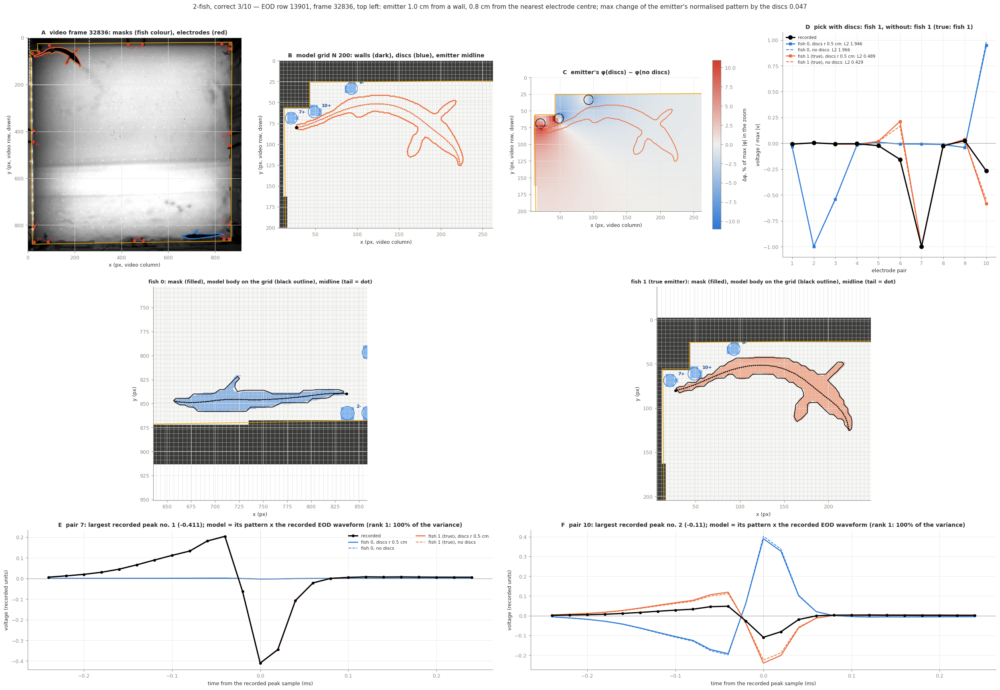

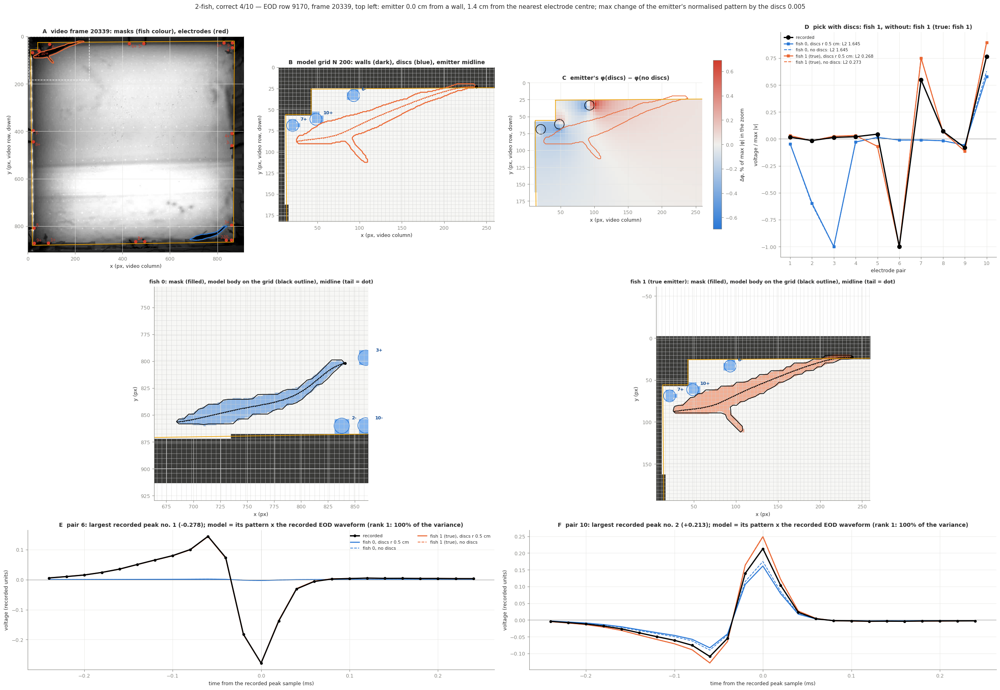

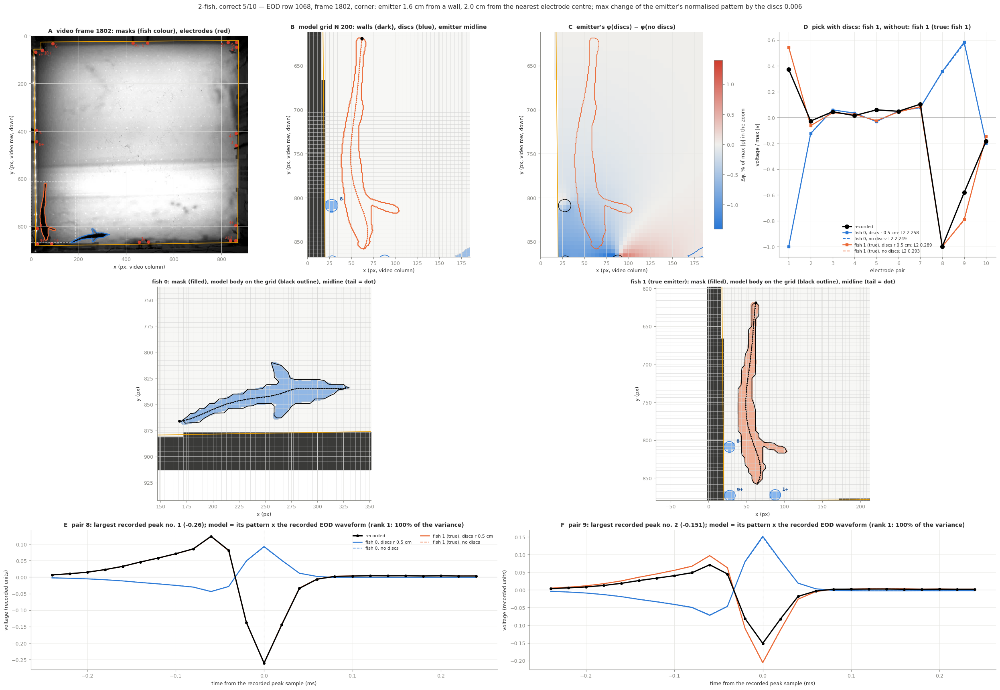

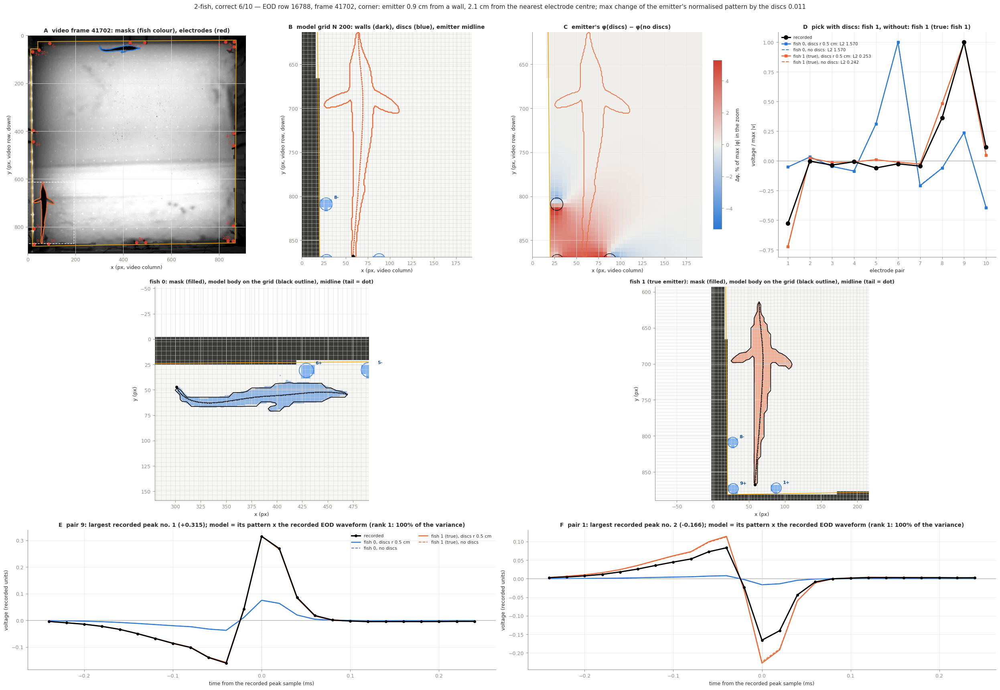

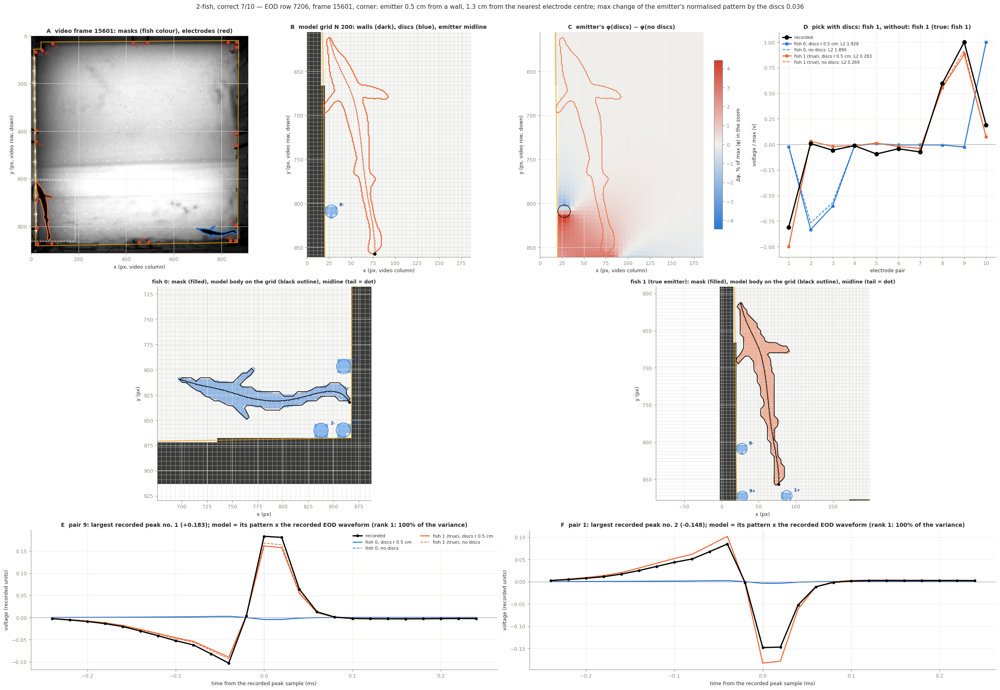

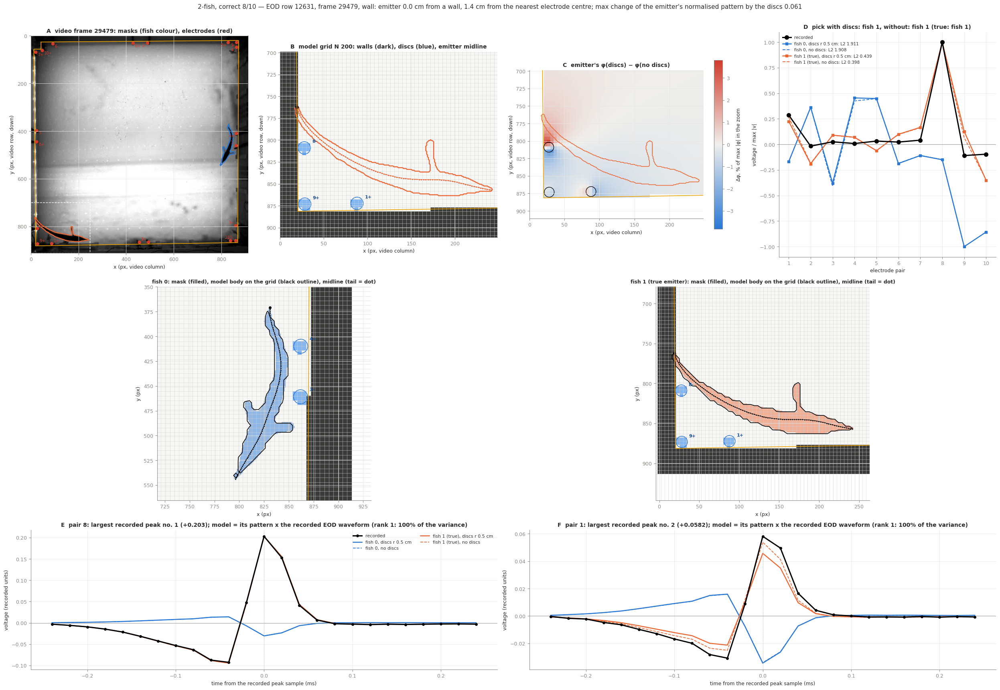

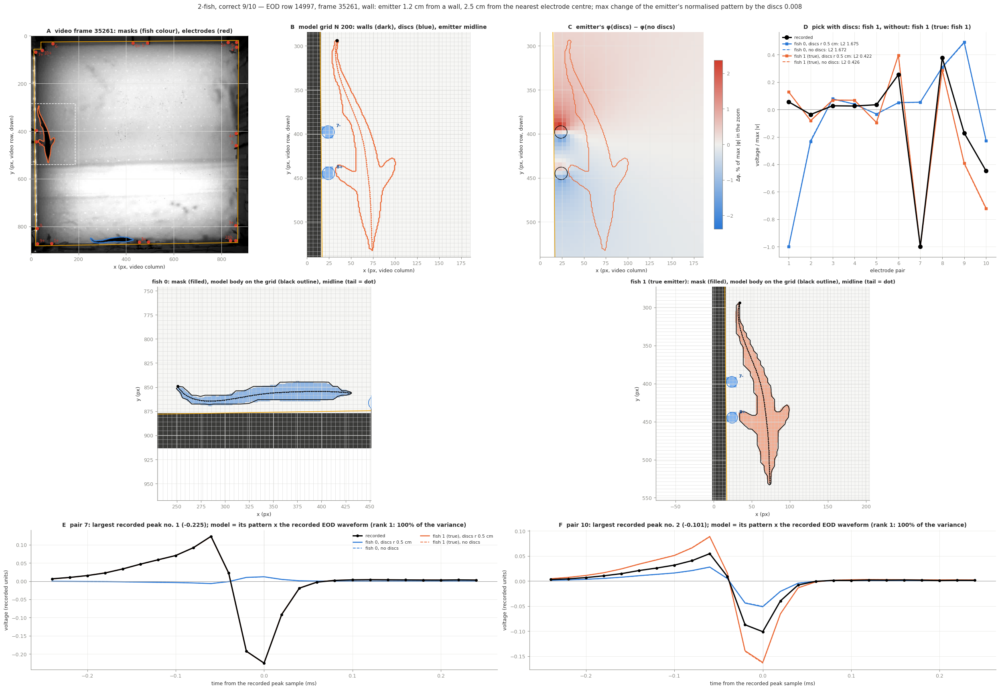

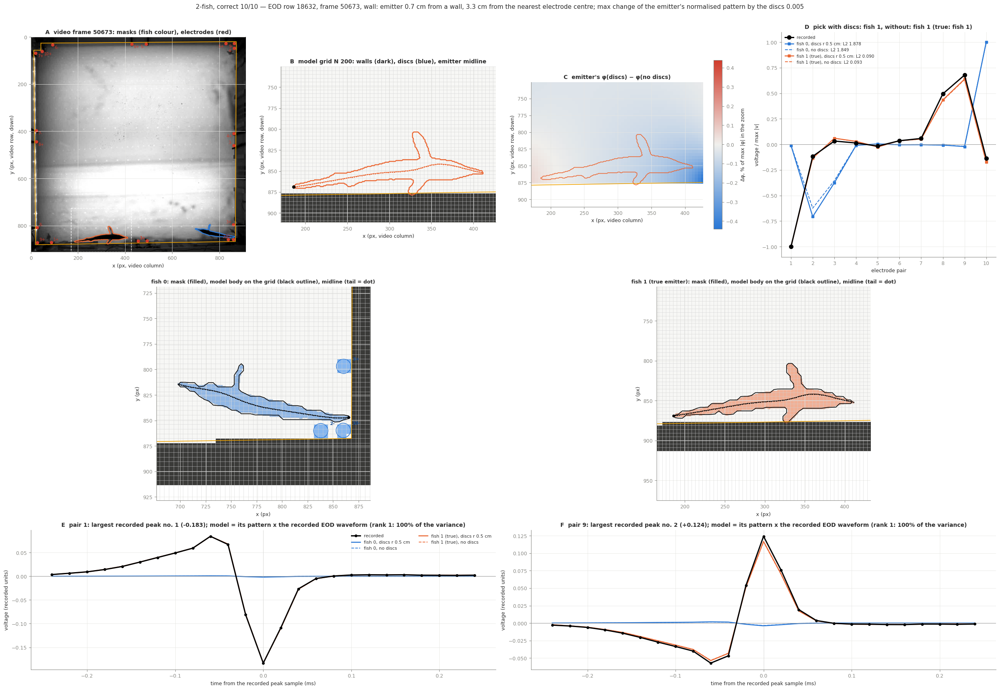

In [5]:
rows_2_correct = [plot_example('2-fish', i, info, n) for n, (i, info) in
                          enumerate(SEL['2-fish'][SEL['2-fish'].outcome == 'correct'].iterrows(), 1)]

### 2-fish: wrong assignments (emitter by a wall / in a corner)

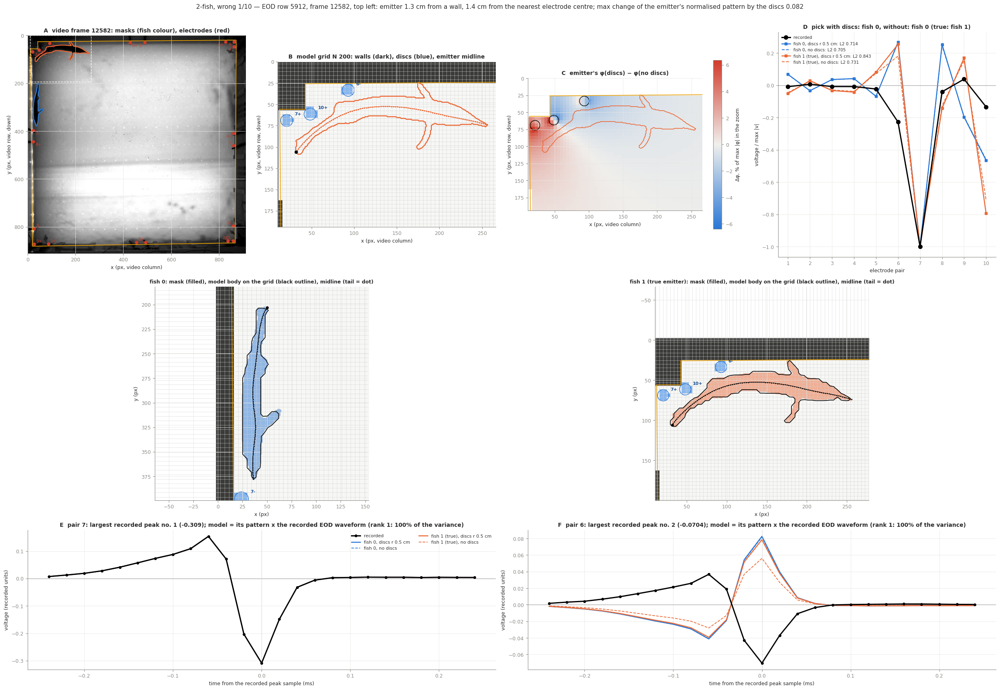

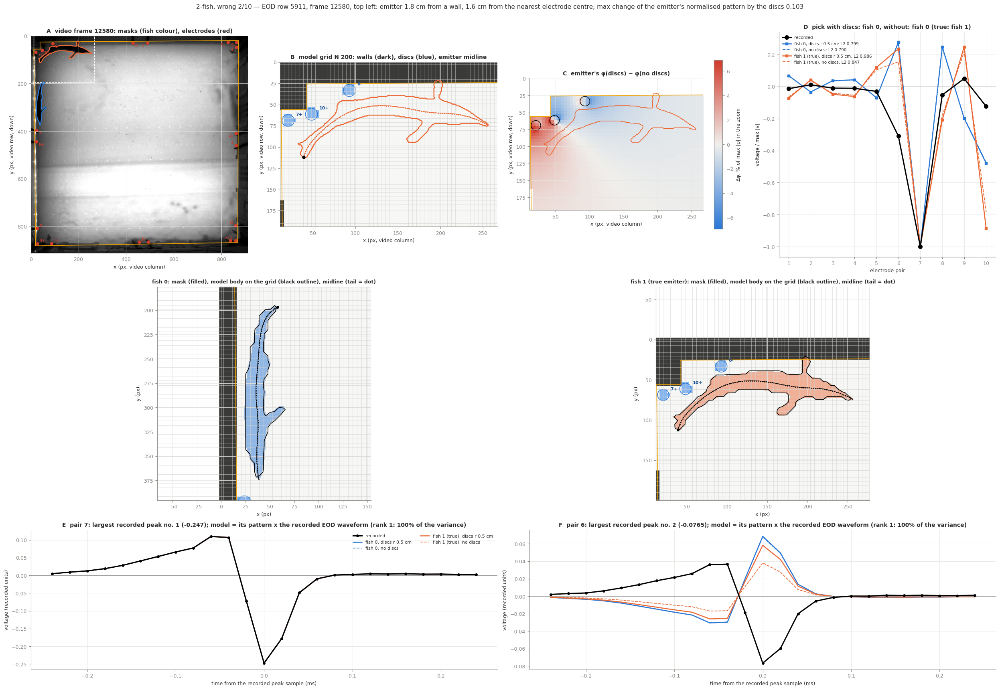

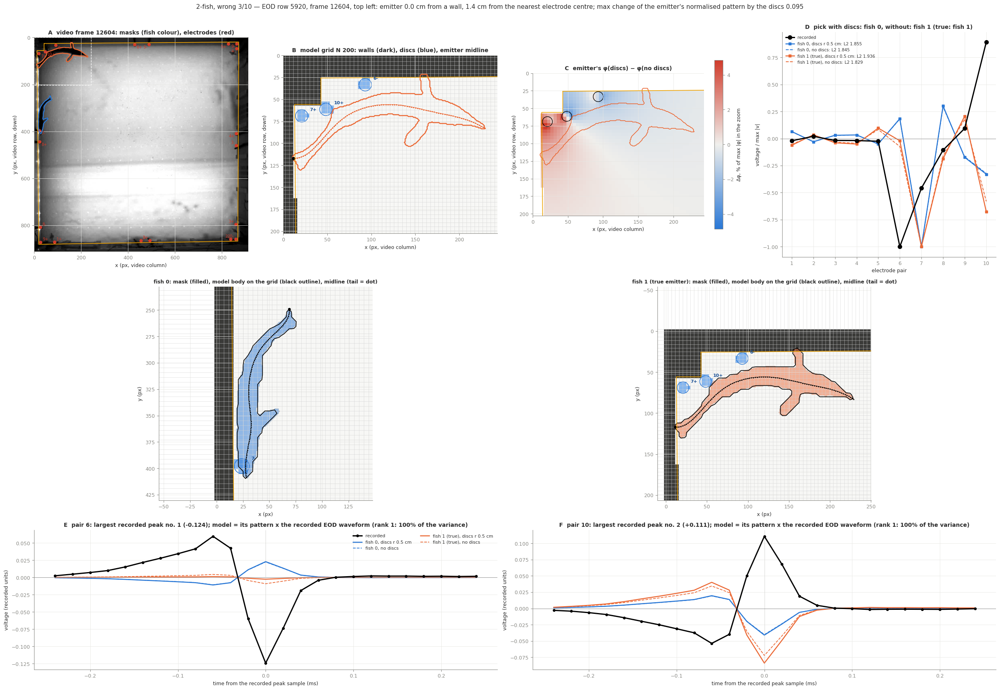

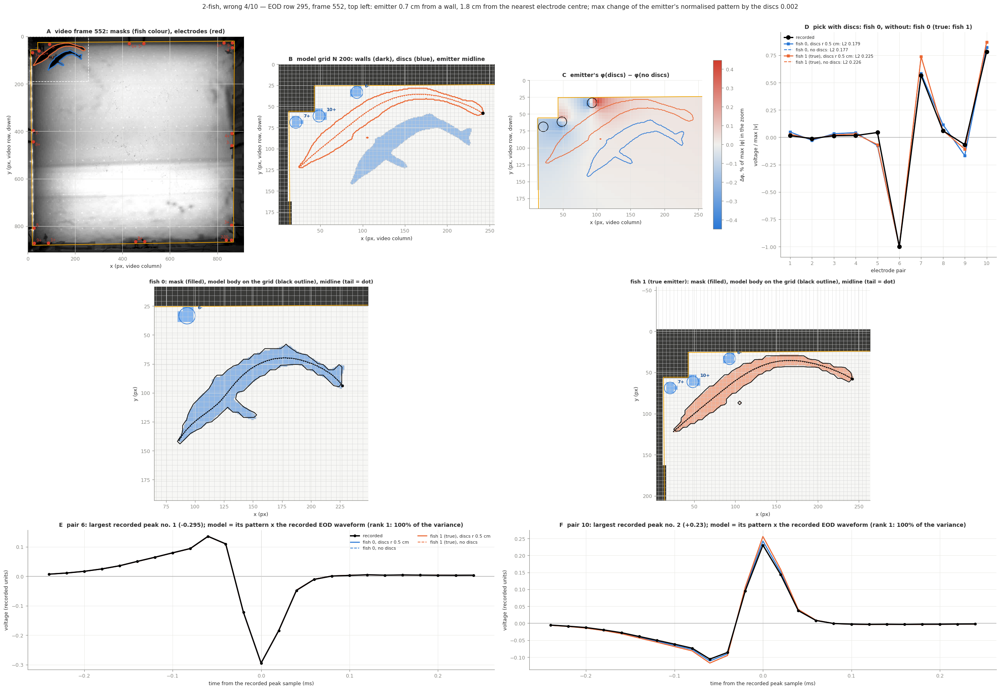

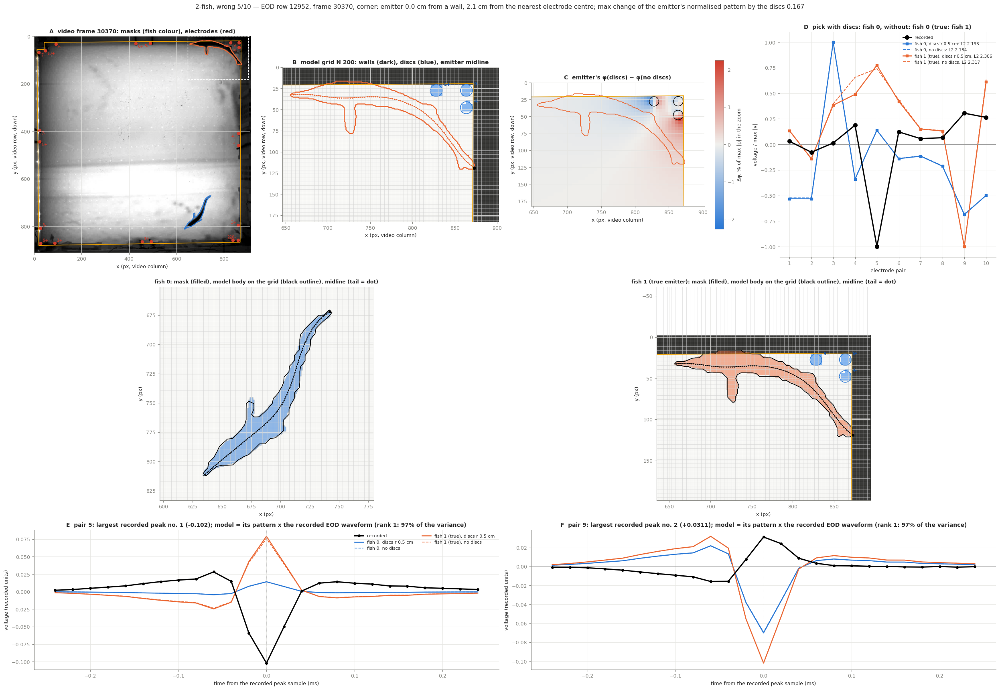

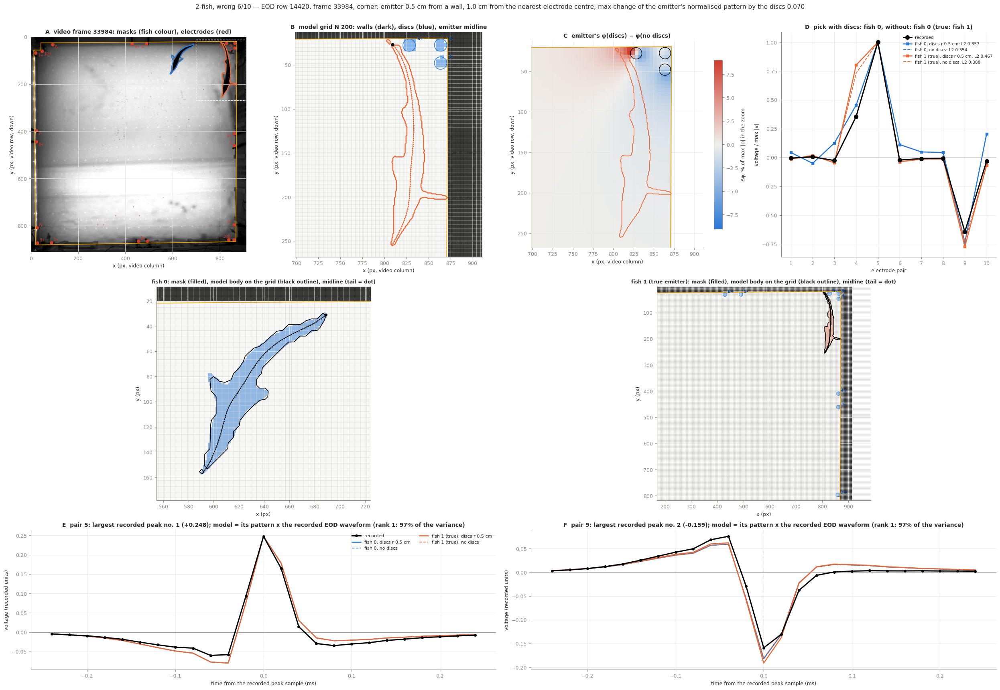

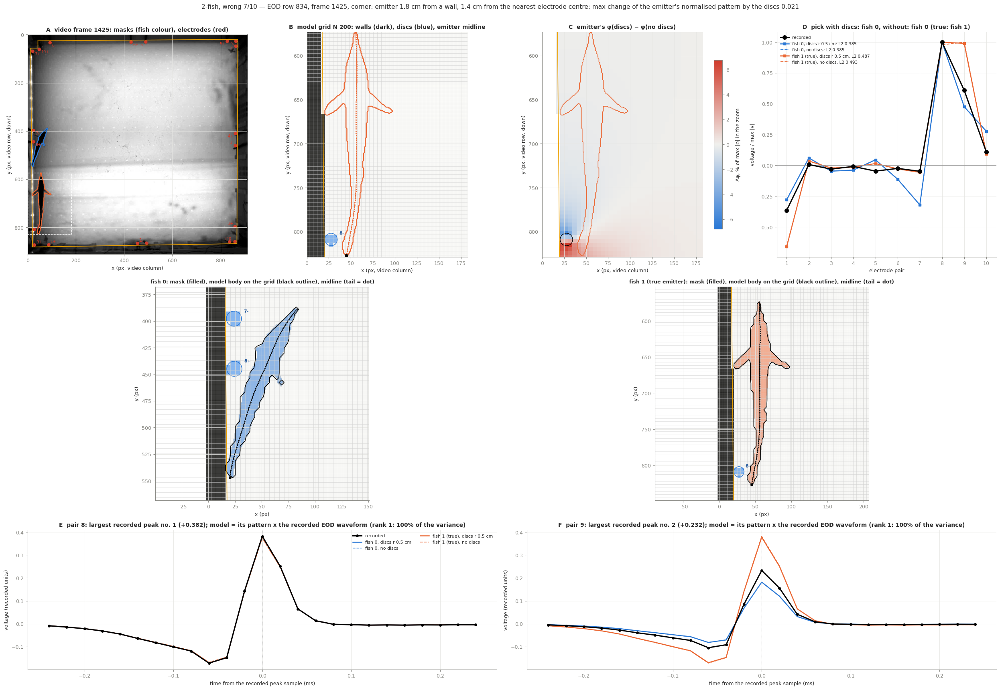

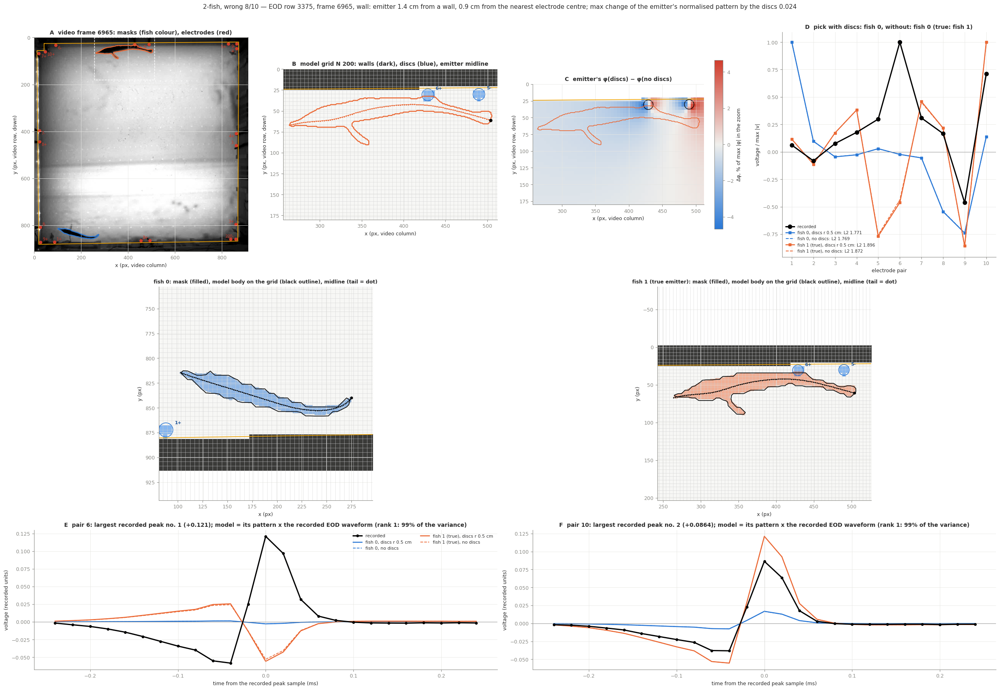

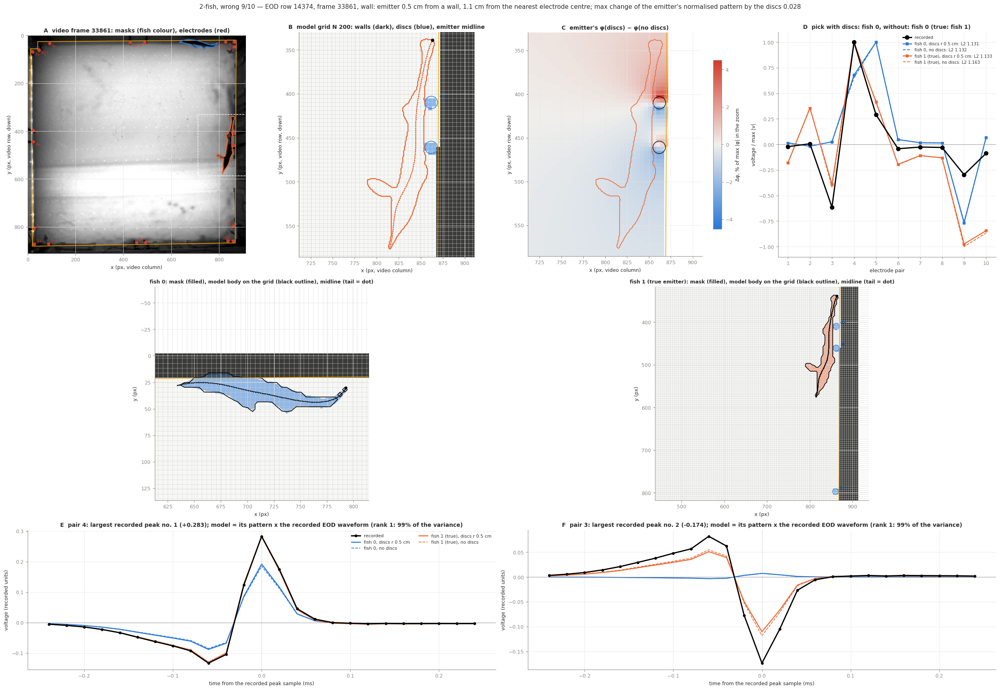

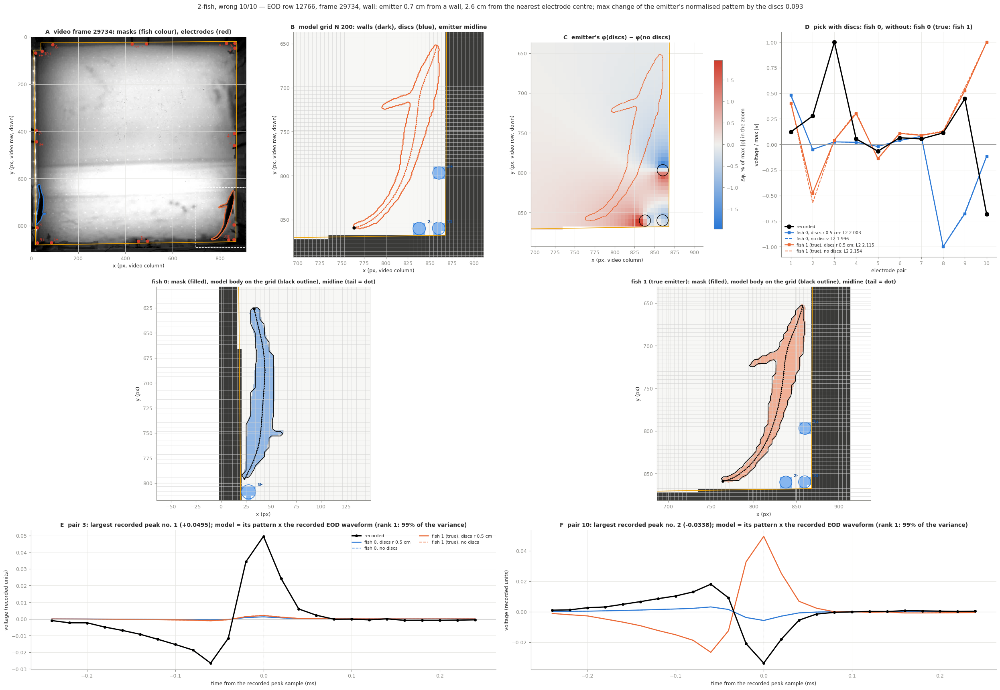

In [6]:
rows_2_wrong = [plot_example('2-fish', i, info, n) for n, (i, info) in
                          enumerate(SEL['2-fish'][SEL['2-fish'].outcome == 'wrong'].iterrows(), 1)]

### 3-fish: correct assignments (emitter by a wall / in a corner)

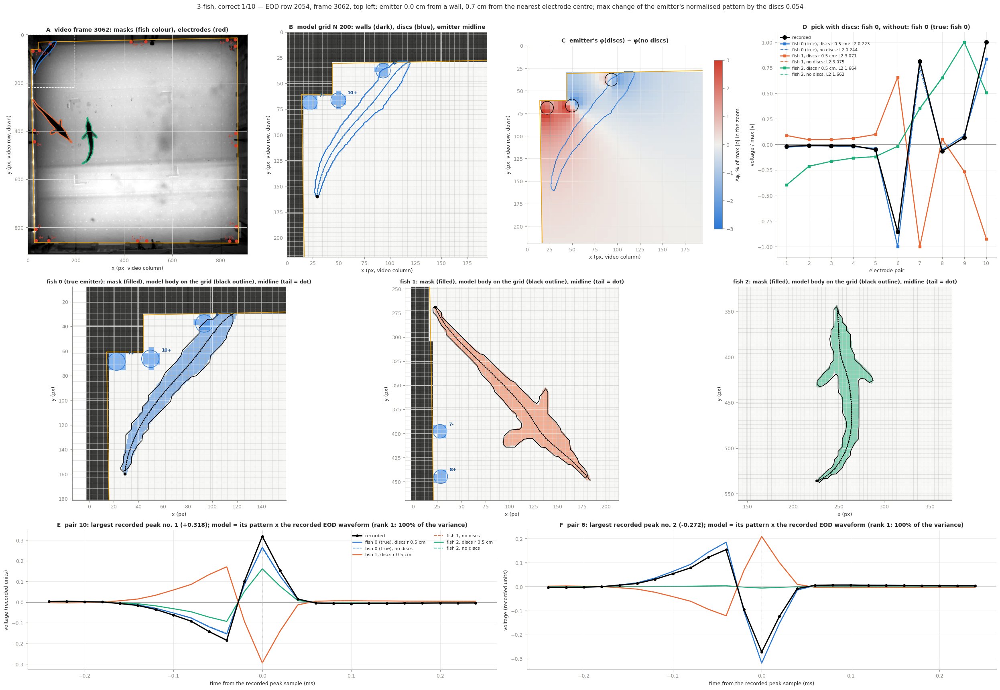

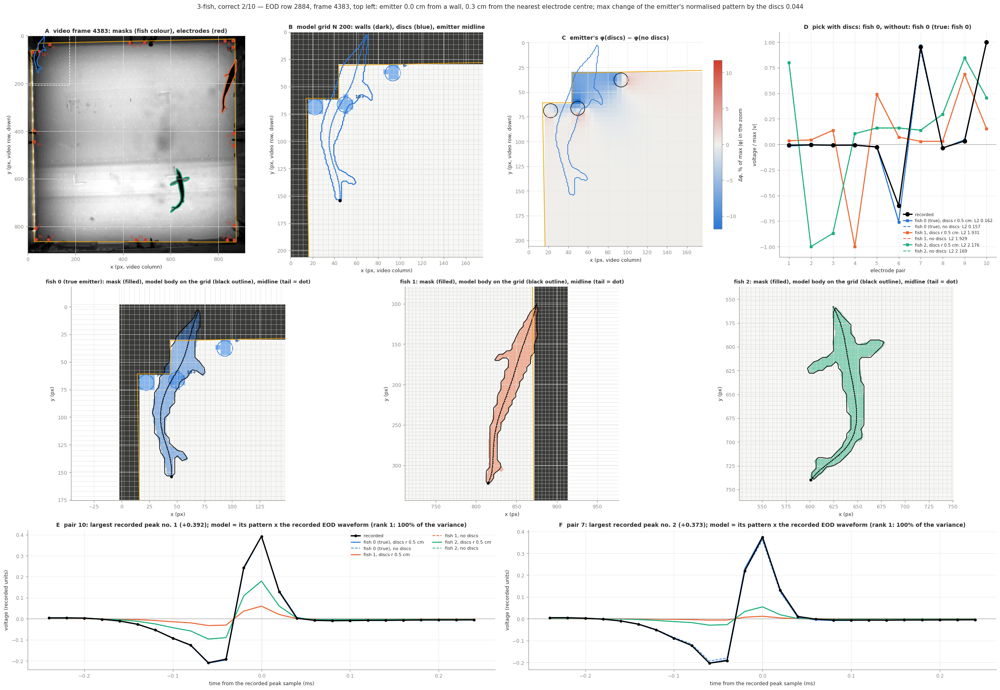

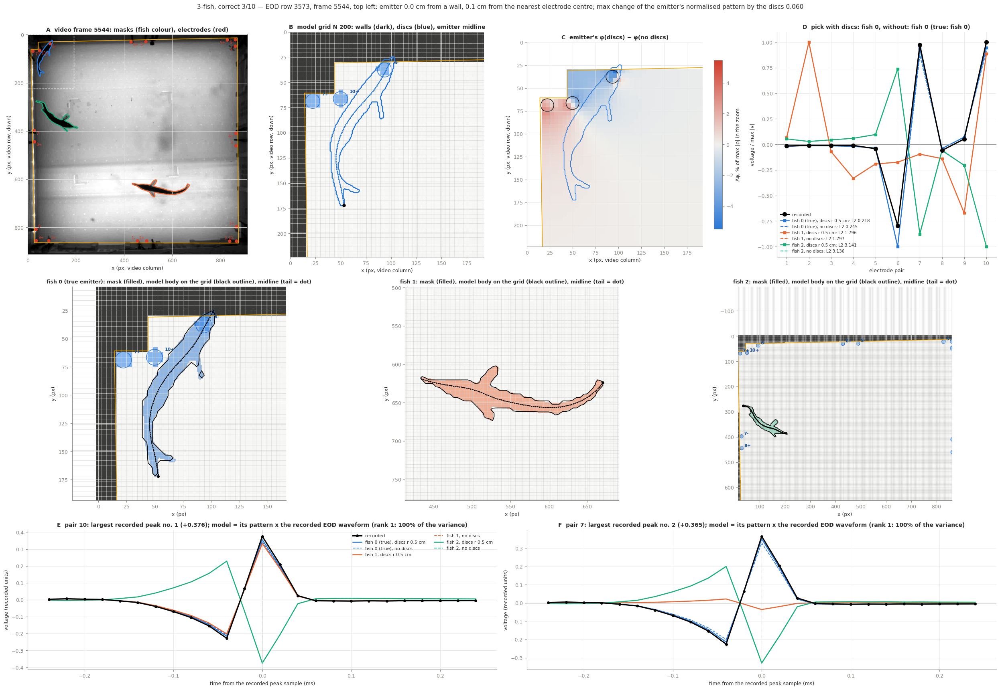

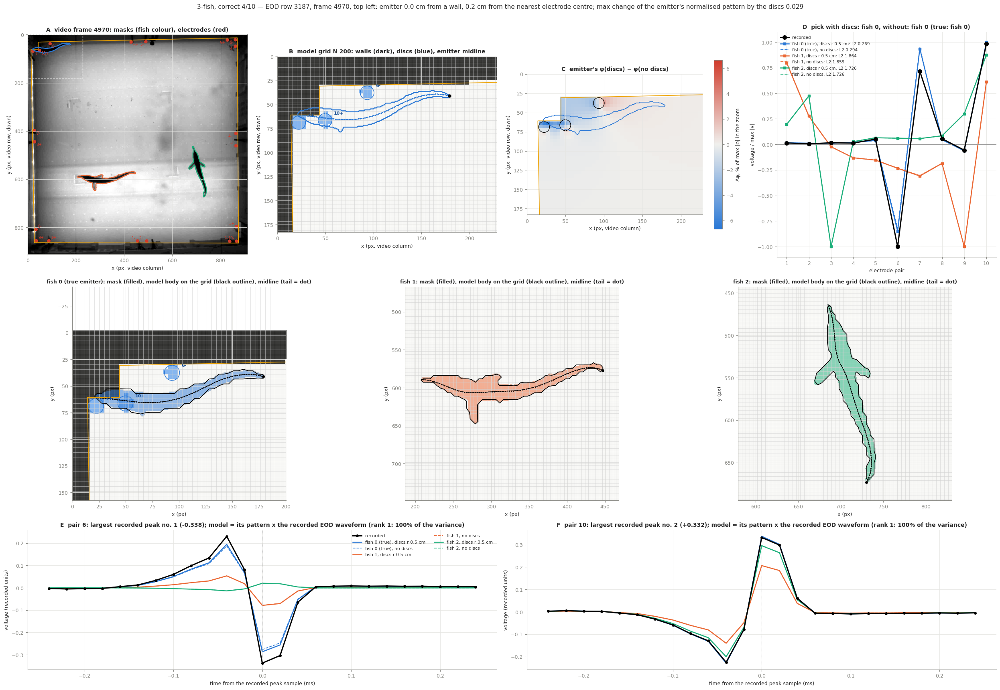

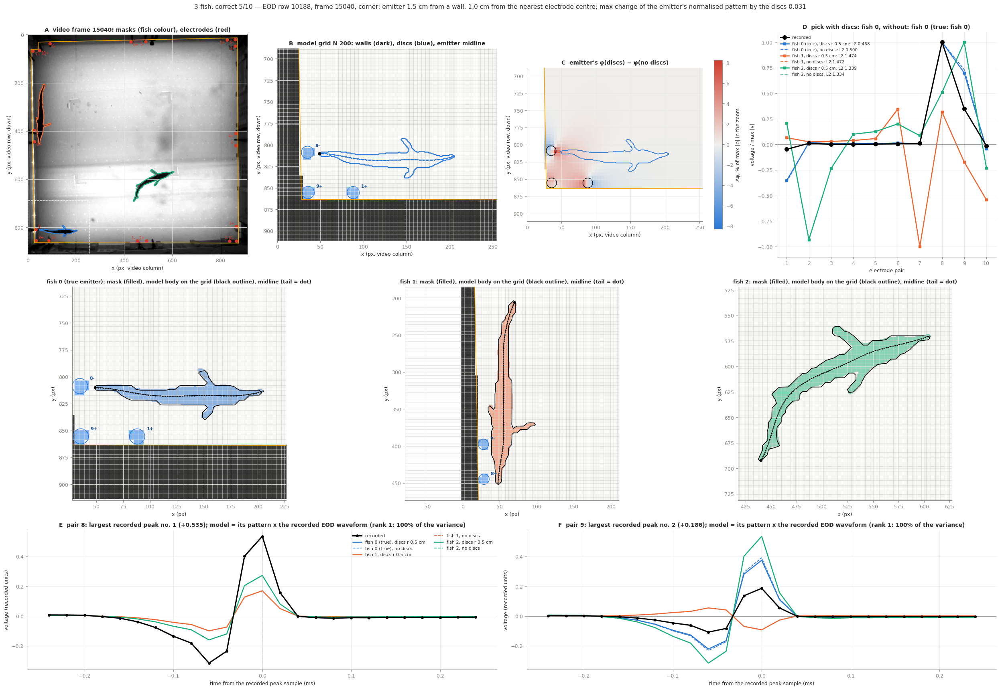

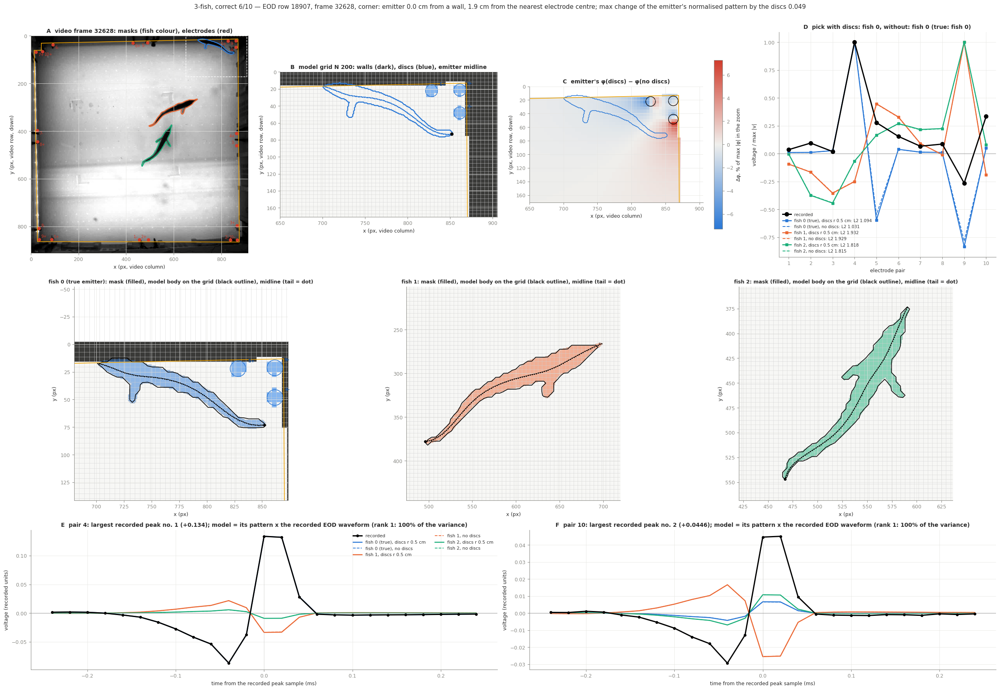

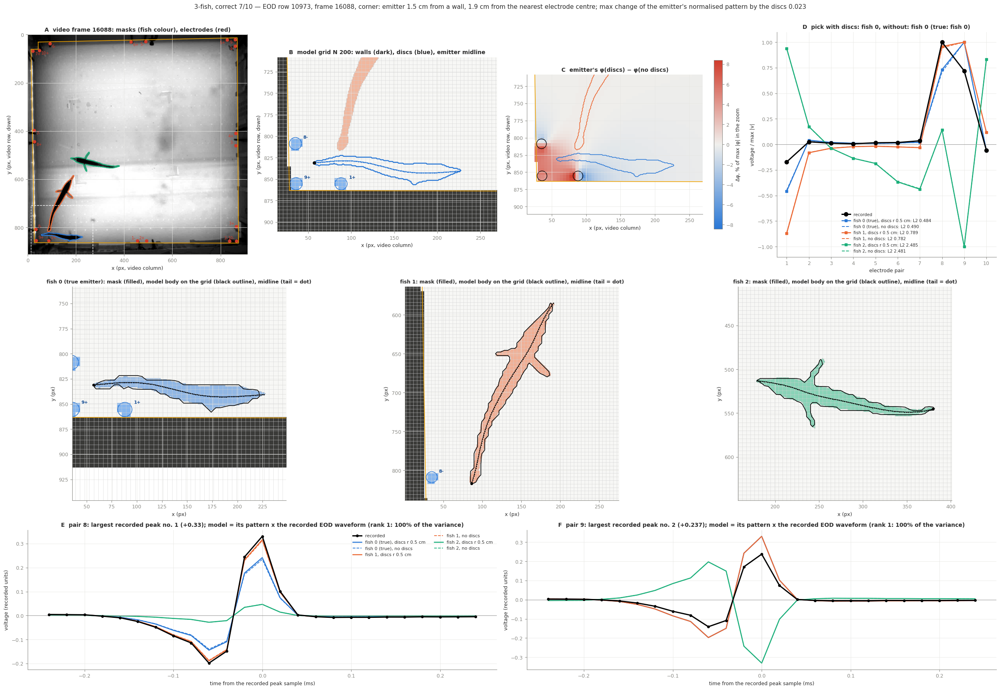

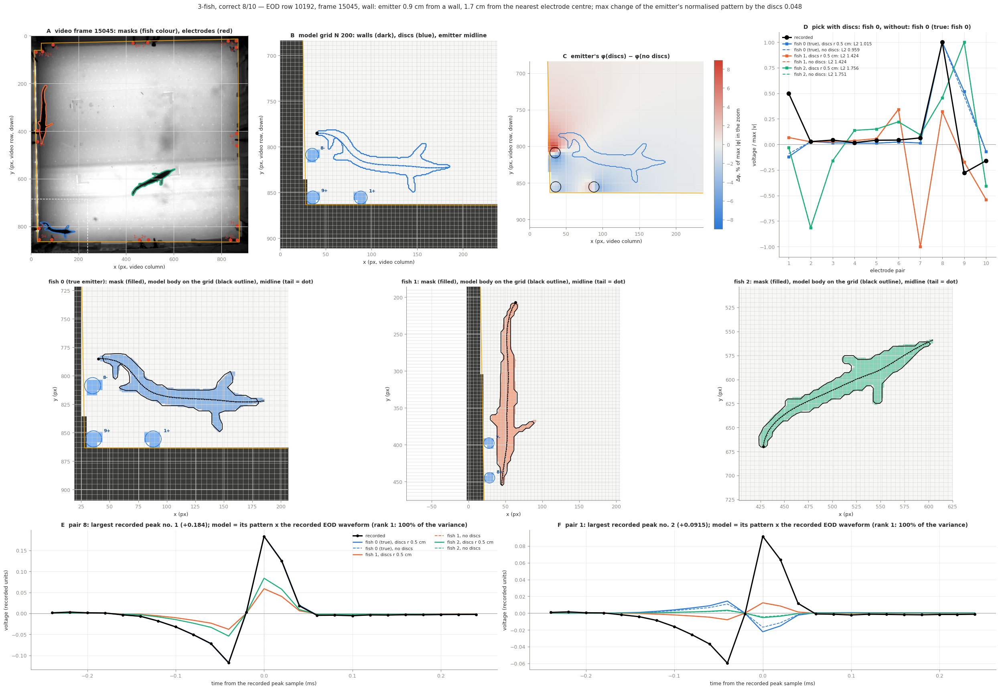

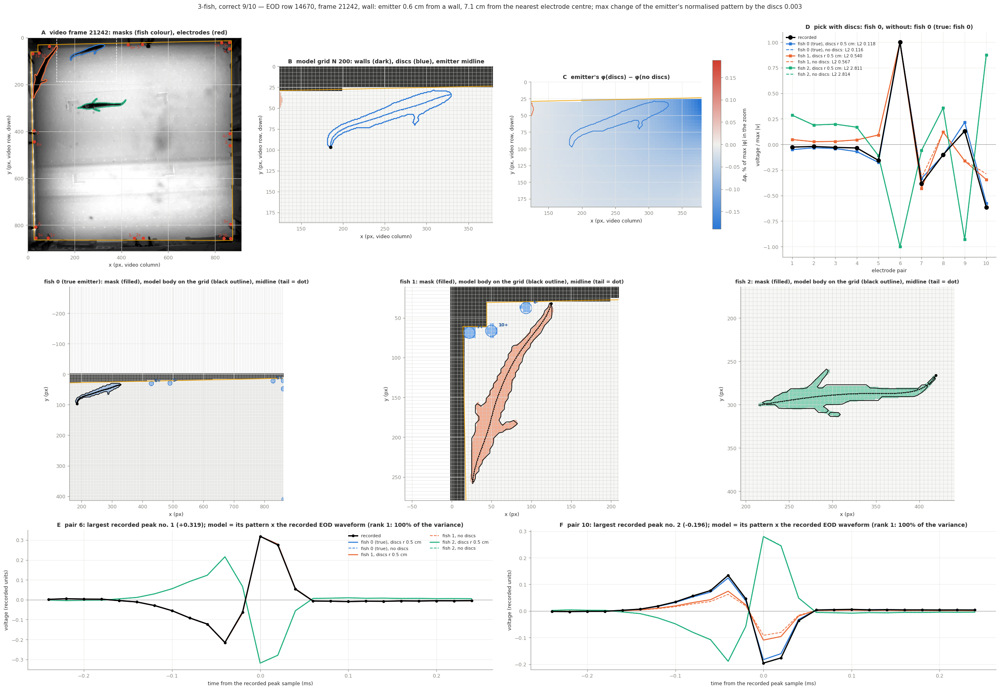

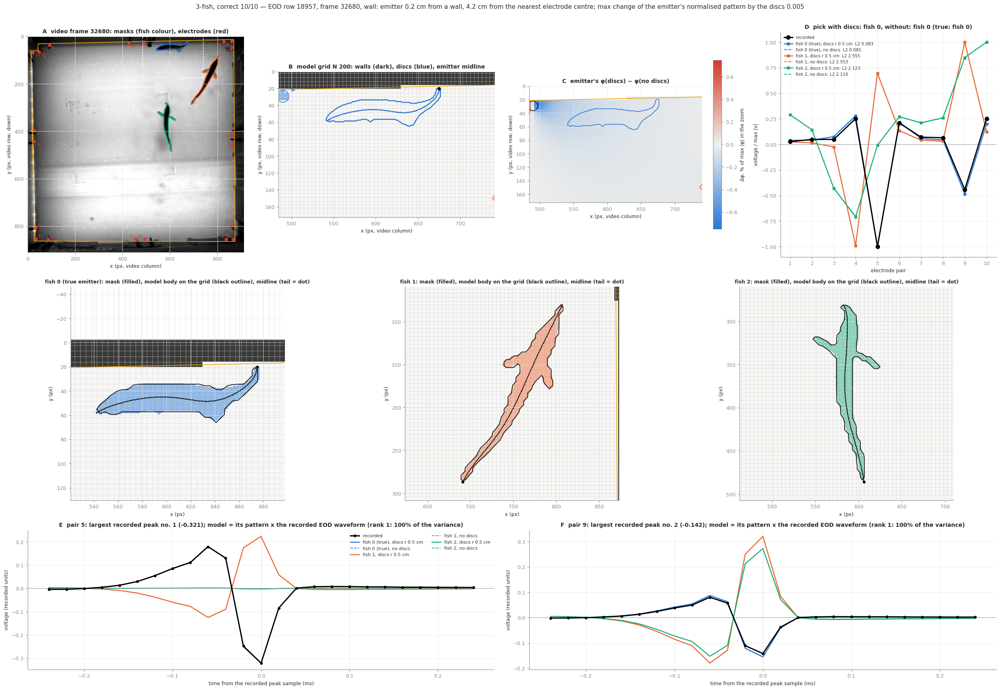

In [7]:
rows_3_correct = [plot_example('3-fish', i, info, n) for n, (i, info) in
                          enumerate(SEL['3-fish'][SEL['3-fish'].outcome == 'correct'].iterrows(), 1)]

### 3-fish: wrong assignments (emitter by a wall / in a corner)

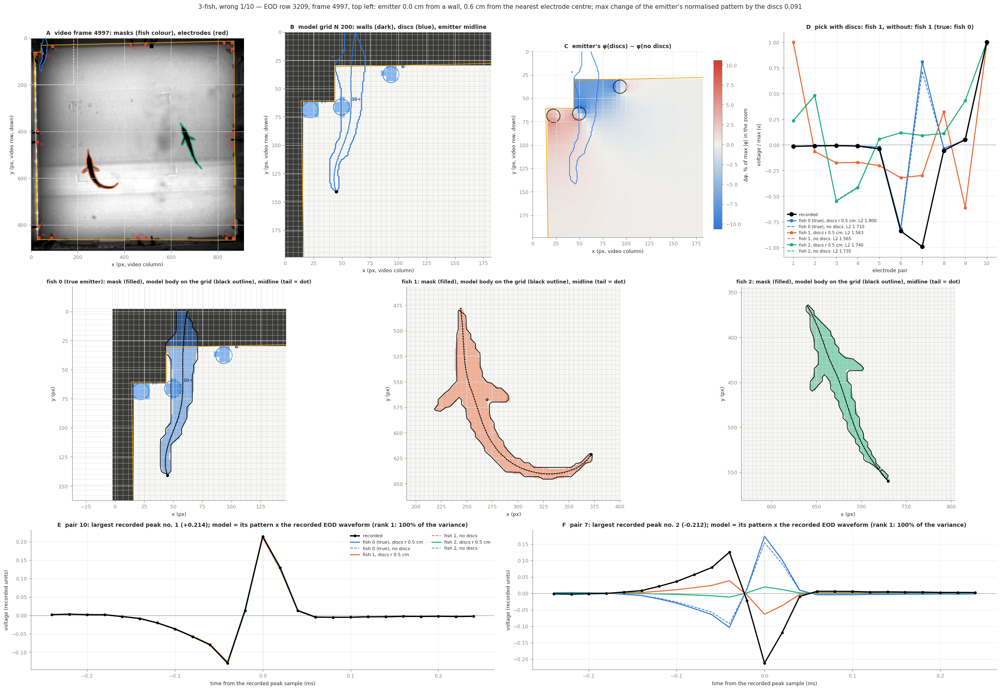

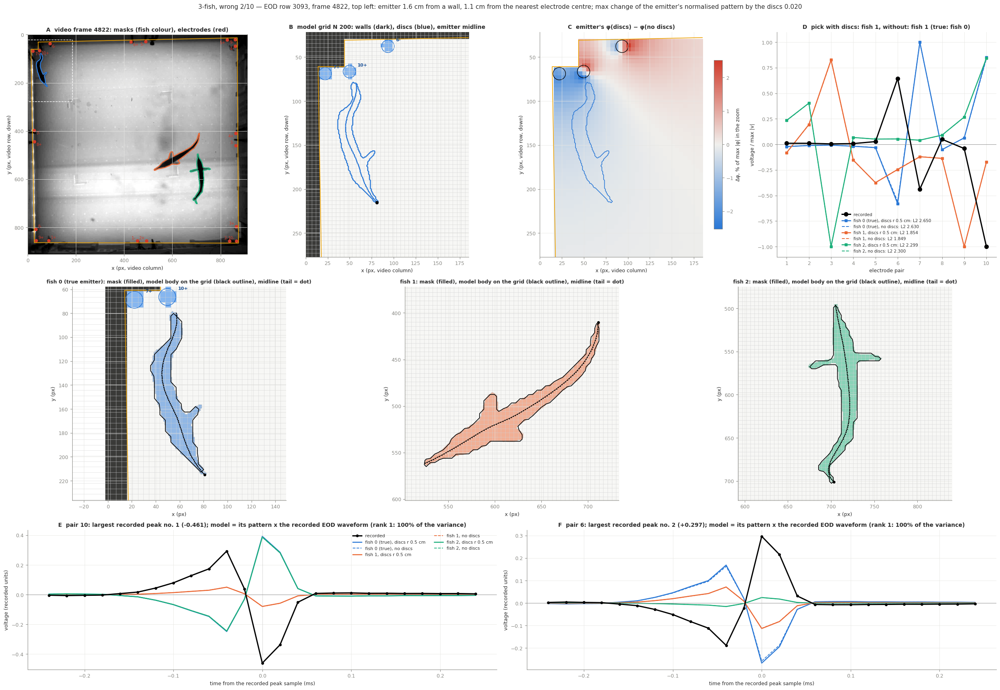

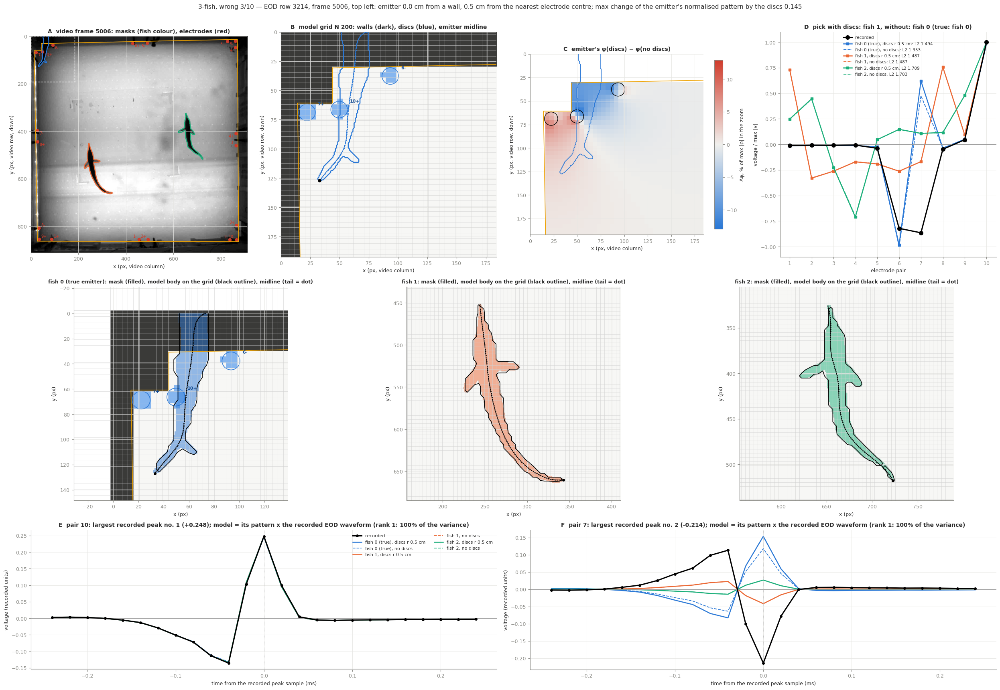

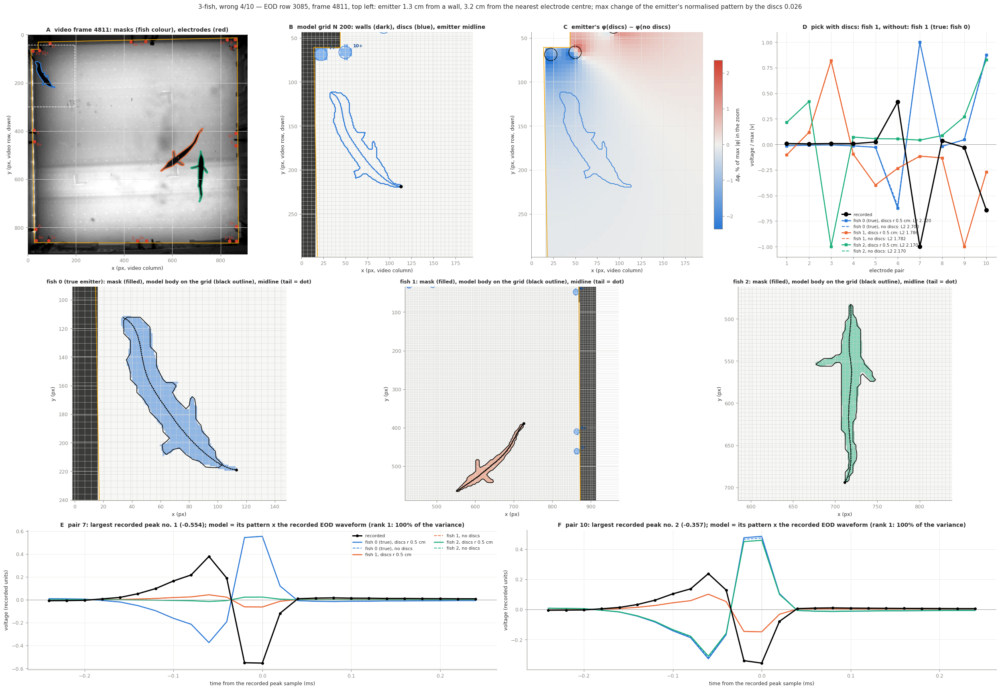

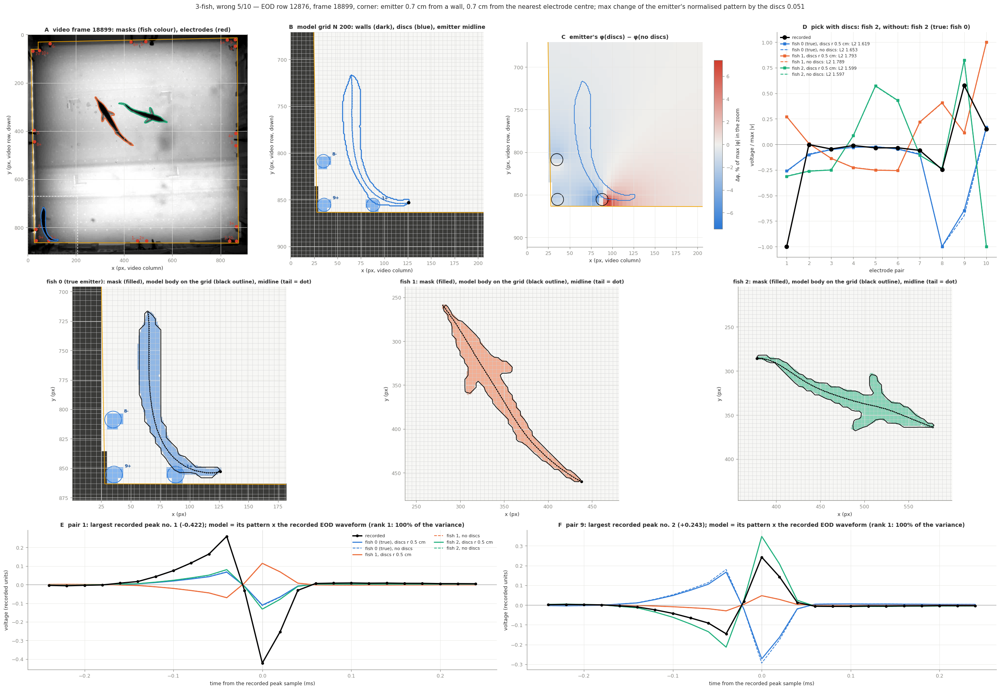

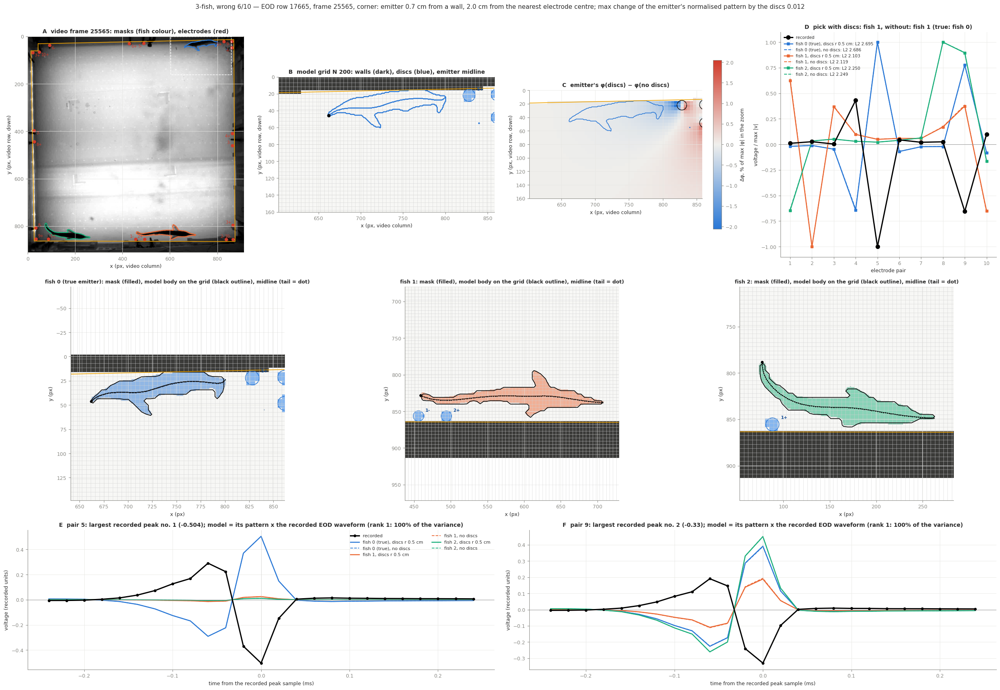

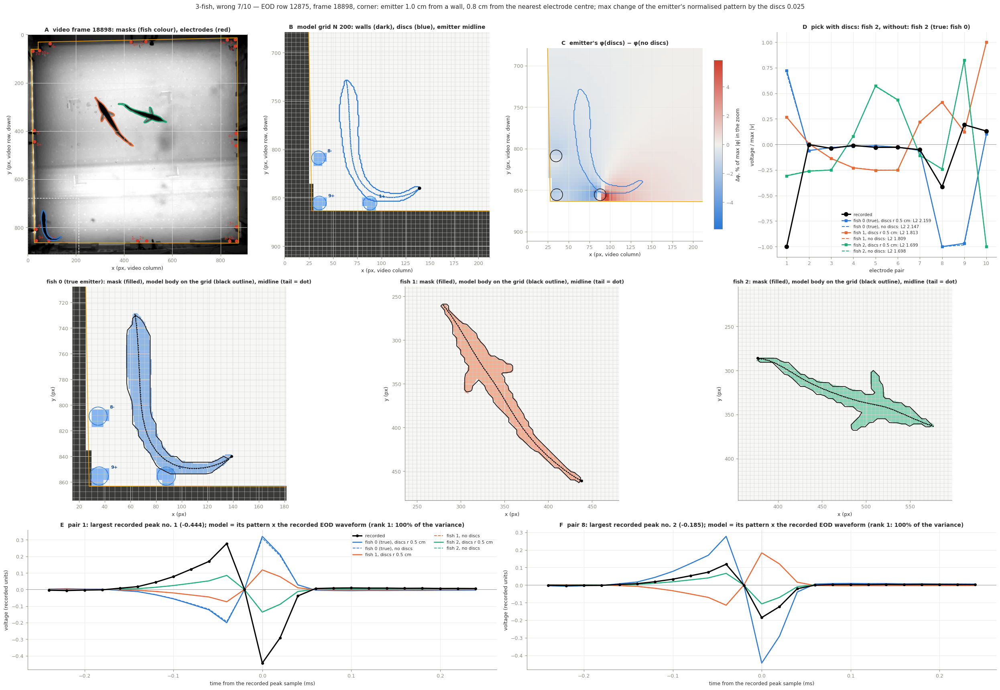

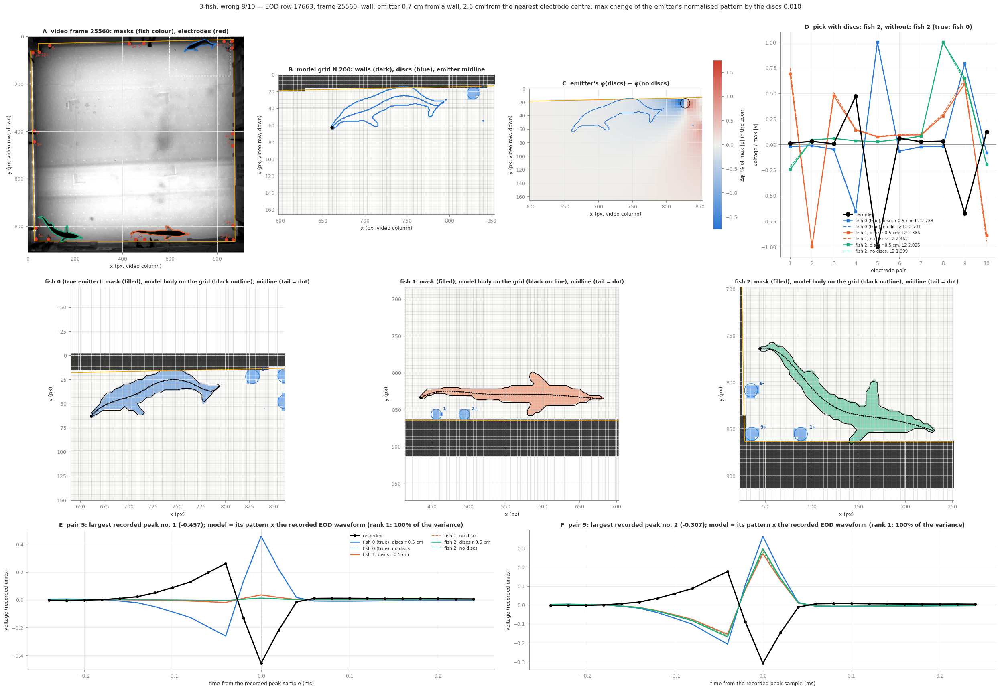

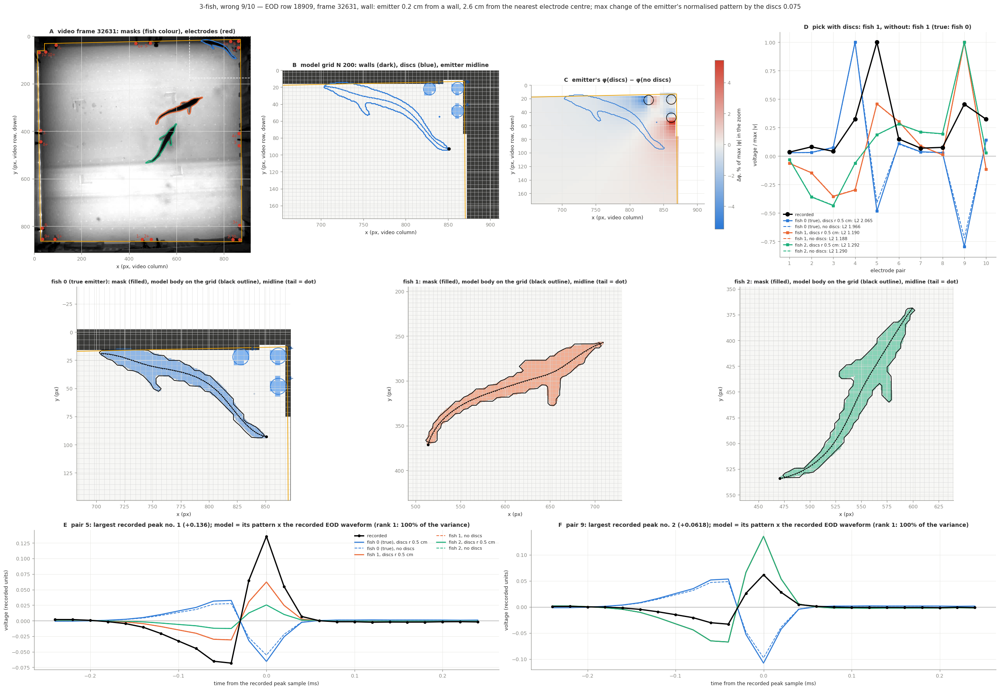

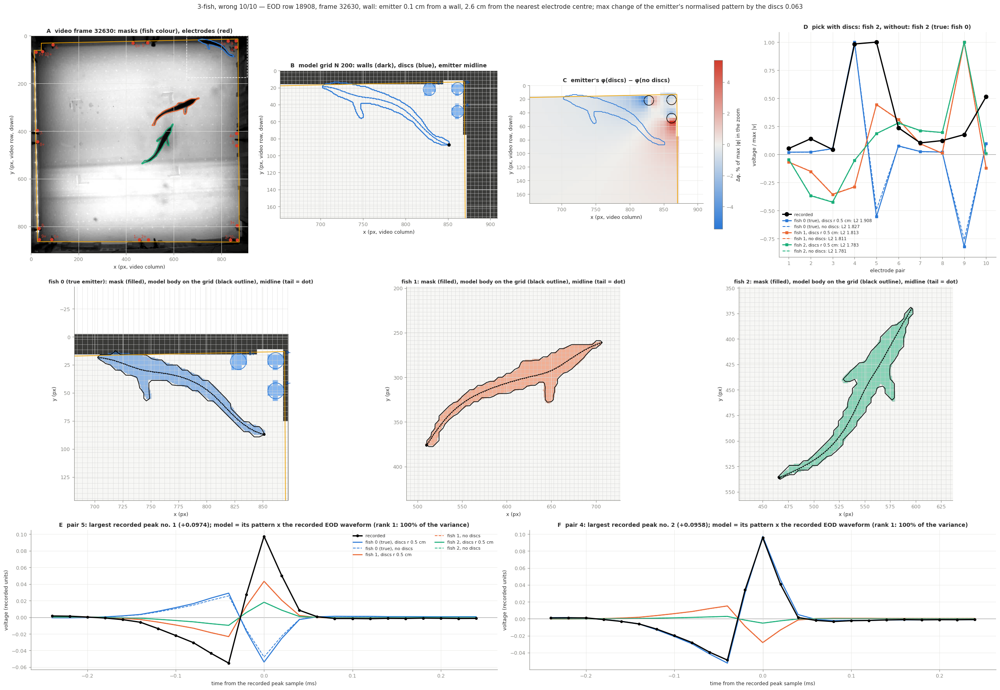

In [8]:
rows_3_wrong = [plot_example('3-fish', i, info, n) for n, (i, info) in
                          enumerate(SEL['3-fish'][SEL['3-fish'].outcome == 'wrong'].iterrows(), 1)]

## 4. Summary of the 40 examples

In [9]:
S = pd.DataFrame(rows_2_correct + rows_2_wrong + rows_3_correct + rows_3_wrong)
S.to_csv('results/eod_assignment_3_fish_silent/Nov_10_2026/debug_electrodes/summary_40_examples.csv', index=False)
display(S.round(3))
display(S.groupby(['rec', 'outcome'])[['wall_cm', 'electrode_cm', 'pattern_change']].median().round(3))

,rec,outcome,eod_row,Frame,region,wall_cm,electrode_cm,pattern_change,pick_discs,pick_none,L2 fish 0 | no discs,L2 fish 1 | no discs,L2 fish 0 | discs r 0.5 cm,L2 fish 1 | discs r 0.5 cm,L2 fish 2 | no discs,L2 fish 2 | discs r 0.5 cm
0,2-fish,correct,3071,6141,top_left,2.111,3.072,0.008,1,1,2.106,0.077,2.111,0.083,NaN,NaN
1,2-fish,correct,8012,17592,top_left,0.675,0.186,0.069,1,1,1.234,0.352,1.234,0.429,NaN,NaN
2,2-fish,correct,13901,32836,top_left,0.988,0.799,0.047,1,1,1.966,0.429,1.946,0.489,NaN,NaN
3,2-fish,correct,9170,20339,top_left,0.010,1.363,0.005,1,1,1.645,0.273,1.645,0.268,NaN,NaN
4,2-fish,correct,1068,1802,corner,1.596,1.961,0.006,1,1,2.249,0.293,2.258,0.289,NaN,NaN
5,2-fish,correct,16788,41702,corner,0.898,2.127,0.011,1,1,1.570,0.242,1.570,0.253,NaN,NaN
6,2-fish,correct,7206,15601,corner,0.540,1.323,0.036,1,1,1.890,0.269,1.928,0.283,NaN,NaN
7,2-fish,correct,12631,29479,wall,0.014,1.366,0.061,1,1,1.908,0.398,1.911,0.439,NaN,NaN
8,2-fish,correct,14997,35261,wall,1.204,2.467,0.008,1,1,1.672,0.426,1.675,0.422,NaN,NaN
9,2-fish,correct,18632,50673,wall,0.682,3.318,0.005,1,1,1.849,0.093,1.878,0.090,NaN,NaN


wall_cm  electrode_cm  pattern_change
rec    outcome                                       
2-fish correct    0.790         1.664           0.010
       wrong      0.736         1.432           0.076
3-fish correct    0.107         1.348           0.038
       wrong      0.655         1.539           0.038

## 5. Electrode effect against the distance to the nearest electrode (every clean-good EOD)

For every clean-good EOD: the largest change of the true emitter's normalised pattern caused by the discs (r 0.5 cm), and of
every other fish's, against that fish's distance (midline, nearest point) to the nearest electrode centre. Lines: median and
90th percentile per distance bin.

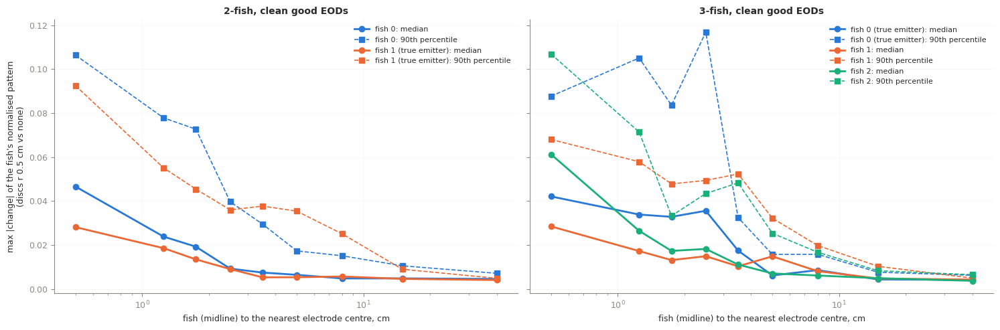

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
BINS = np.array([0, 1, 1.5, 2, 3, 4, 6, 10, 20, 60])
for a, (rec, r) in zip(axs, REC.items()):
    D, ctx = DATA[rec], CTX[rec]['discs r 0.5 cm']; pair_ids = [p for p, _, _ in ctx['pairs']]
    pts = electrode_points(ctx['pairs'])[:, ::-1] * (P - 1)
    res = D['res']; nf = len(ctx['fish']); idx = np.flatnonzero(D['clean'])
    for f in range(nf):
        cols = [f'u{f}_raw_p{q}' for q in pair_ids]
        u0, u1 = (res[v][cols].to_numpy()[idx] for v in VER)
        ch = np.abs(u1 / np.abs(u1).max(1, keepdims=True) - u0 / np.abs(u0).max(1, keepdims=True)).max(1)
        de = np.array([np.linalg.norm(D['mid_px'][int(k)][f][:, None] - pts[None], axis=-1).min() / PX_PER_CM
                       if np.isfinite(D['mid_px'][int(k)][f]).all() else np.nan for k in res['no discs'].Frame.to_numpy()[idx]])
        ok = np.isfinite(ch) & np.isfinite(de); b = np.digitize(de[ok], BINS) - 1
        xm = [(BINS[j] + BINS[j + 1]) / 2 for j in range(len(BINS) - 1)]
        med = [np.median(ch[ok][b == j]) if (b == j).sum() >= 10 else np.nan for j in range(len(BINS) - 1)]
        p90 = [np.percentile(ch[ok][b == j], 90) if (b == j).sum() >= 10 else np.nan for j in range(len(BINS) - 1)]
        lab = f"fish {f}{' (true emitter)' if f == r['emitter'] else ''}"
        a.plot(xm, med, 'o-', color=FISH_COL[f], lw=2, label=f'{lab}: median')
        a.plot(xm, p90, 's--', color=FISH_COL[f], lw=1.2, label=f'{lab}: 90th percentile')
    a.set_xscale('log'); a.set_xlabel("fish (midline) to the nearest electrode centre, cm"); a.set_title(f'{rec}, clean good EODs')
    a.grid(alpha=0.3); a.legend(fontsize=8, frameon=False)
axs[0].set_ylabel("max |change| of the fish's normalised pattern\n(discs r 0.5 cm vs none)")
plt.tight_layout(); fig.savefig('results/eod_assignment_3_fish_silent/Nov_10_2026/debug_electrodes/electrode_effect_vs_distance.png', dpi=110)
plt.show()

## 6. Findings

**The electrodes change the model's patterns only a little, even for a fish touching them.** The change of a fish's normalised
pattern (discs r 0.5 cm vs none) is a median of 0.03–0.05 (90th percentile ~0.1) when the fish is within 1 cm of an electrode,
and ~0.005 beyond 10 cm (section 5). In the 40 examples the median change is 0.01–0.08, while the true emitter's L2 is
0.27 (2-fish) to 0.42 (3-fish) and the gap to the next fish is usually larger than the change. So picks rarely flip: 38 of the
40 examples get the same fish with and without discs, and both flips (2-fish row 5920, 3-fish row 3214) go from right without
discs to wrong with them.

**Why so small: a recording electrode floats.** It draws no net current, so a perfect conductor settles at the average of the
potential over its rim. Where the potential has no sources inside the disc it is harmonic, and its average over a circle equals
its value at the centre (mean-value property). So a conducting disc reads almost exactly what the bare point at its centre
reads: the readout the model used before. What changes is second order. The disc's induced dipole falls off as (r/d)² (r 0.5 cm,
the next electrode ≥ 2 cm away), plus small knock-on changes through the walls and the other fish's bodies. Larger changes
(up to ~0.15–0.19) need current poles inside or at the rim of a disc (a fish lying on the electrode), as in 2-fish row 12952
and 3-fish row 3214. Panel C shows this: the potential changes by up to ~10 % right around the discs, and by little elsewhere.

**The wrong assignments by the walls are not caused by the electrodes.** 18 of the 20 wrong examples are wrong with and
without discs. The mismatch between model and recording at those EODs comes from elsewhere: the shape of the emitter's field
near walls and corners, its midline and sources, and the electrode positions there.

**Masks past the tank outline (top-left corner).** In some top-left EODs the emitter's mask and midline run beyond the fitted
walls, into the 2 cm cut-out and above the top wall. 3-fish row 3214, frame 5006 is an example: the fish reaches ~2 cm above
the top wall, so `confine_sources` pushes its poles onto the wall and the model gets pair 7 wrong in sign. This is rare on clean
good frames:
- emitter midline > 1 cm outside the outline: 3-fish 176 of 8,972 EODs (96.0 % correct there, 7 of the 155 wrong ones);
  2-fish 3 of 11,803;
- 0.3–1 cm outside: 3-fish 142 (100 % correct), 2-fish 42 (95.2 %).

The fish may be swimming high (closer to the camera, so it appears pushed outwards), or the outline may be slightly off in that
corner.
